# House Price Prediction — Modelling Pipeline

**Course:** Machine Learning, Concept Integration Assessment 2 (BITS Pilani Dubai)  
**Team:** Nabhya Yadav, MVS Maheedhar Reddy, Nivedita Mahesh, Ponnamanda Hruday Manas

This notebook runs the full pipeline on the Ames Housing data (Kaggle `train.csv`), from setup to the final test-set evaluation. Each section starts with a short note covering **what** the step does, **why** it is needed and **what to look for** in the output.

To rebuild everything in a fresh Colab session, use **Runtime → Run all**.

## 0. Setup

**What:** installs the libraries Colab may lack, imports everything, and downloads `train.csv` into `data/`.

**Why:** Colab sessions are temporary, so every file in `/content/` is deleted when the session ends. Putting all setup at the top means one "Run all" rebuilds the session from nothing. We fix a random seed (`RANDOM_STATE = 42`) so the split and every model give the same results on every run (reproducibility).

**What to look for:** the printed library versions (scikit-learn must be **≥ 1.4** for `TargetEncoder`), and a confirmation that `data/train.csv` exists.

In [87]:
# Install or upgrade the libraries we rely on.
# %pip (not !pip) installs into the kernel this notebook is running on.
# scikit-learn >= 1.4 is required for TargetEncoder (Neighborhood encoding, later).
# -q keeps the install log short.
%pip install -q "scikit-learn>=1.4" "xgboost>=2.0" "shap>=0.44" "gdown>=5.0"

In [88]:
import os
import shutil
import time

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from matplotlib.patches import FancyBboxPatch
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error, r2_score,
                             root_mean_squared_error)
from sklearn.model_selection import (GridSearchCV, KFold, RandomizedSearchCV, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from xgboost import XGBRegressor

# shap is only used in a later section. Importing it here
# means a failed install shows up in the first minute, not at the end of the run.
import shap
import xgboost

# One seed for every random step (split, CV folds, models) so results are reproducible.
RANDOM_STATE = 42

print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("xgboost     :", xgboost.__version__)
print("shap        :", shap.__version__)

pandas      : 2.2.3
numpy       : 2.4.6
scikit-learn: 1.6.1
xgboost     : 3.4.1
shap        : 0.54.1


In [89]:
DATA_DIR = "data"
DATA_PATH = os.path.join(DATA_DIR, "train.csv")
# Shared Google Drive copy of Kaggle's train.csv (the CSV is not committed to git:
# Kaggle's competition rules restrict redistribution).
DRIVE_FILE_ID = "1kh3Fz_JmR75a22_1mxfcWMRTRcHGK-iA"

# Create the folders the rest of the notebook writes into.
for folder in [DATA_DIR, "outputs/figures", "outputs/results"]:
    os.makedirs(folder, exist_ok=True)

# Download only if the file is missing, so re-running this cell does not re-download it.
if not os.path.exists(DATA_PATH):
    gdown.download(id=DRIVE_FILE_ID, output=DATA_PATH, quiet=False)

print("train.csv present:", os.path.exists(DATA_PATH))

train.csv present: True


## 1. Load the data

**What:** reads `train.csv`, drops `Id`, converts `MSSubClass` to text, and separates the **features** (the inputs, `X`) from the **target** (the value we predict, `y`).

**Why:**
- `Id` is just a row number. Keeping it would let a model find accidental patterns in it.
- `MSSubClass` is stored as a number (20, 60, 190, ...), but each number is a code for a dwelling type. Type 60 is not "three times" type 20. Storing it as text makes the pipeline treat it as a **categorical** feature (one-hot encoded later) instead of a quantity.
- The target is `log(1 + SalePrice)`. In EDA, `SalePrice` was strongly right-skewed (skew 1.88); after the log it is almost symmetric (skew 0.12). Kaggle's metric is also RMSE on log price. Predictions are converted back to dollars later with `np.expm1`.

**What to look for:** shape `(1460, 80)` after dropping `Id`; `MSSubClass` dtype `object` (pandas' text type); 79 feature columns.

In [90]:
def load_data(path):
    """Load the Ames training data and apply the type decisions made in EDA.

    Input:  path to Kaggle's train.csv.
    Output: DataFrame without the Id column, with MSSubClass stored as text.
    """
    df = pd.read_csv(path)
    # Id is a row number with no information about the house.
    df = df.drop(columns="Id")
    # MSSubClass is a dwelling-type code, not a quantity, so treat it as categorical.
    df["MSSubClass"] = df["MSSubClass"].astype(str)
    return df


df = load_data(DATA_PATH)

# Features = every column except the price. Target = log price (skew 1.88 -> 0.12 in EDA).
X = df.drop(columns="SalePrice")
y_log = np.log1p(df["SalePrice"])

print("Data shape (rows, columns):", df.shape)
print("Number of features        :", X.shape[1])
print("MSSubClass dtype          :", df["MSSubClass"].dtype)
print("Skew of log price         :", round(y_log.skew(), 2))

Data shape (rows, columns): (1460, 80)
Number of features        : 79
MSSubClass dtype          : object
Skew of log price         : 0.12


**Result:** after dropping `Id`, the data has 1,460 rows and 80 columns (79 features plus `SalePrice`). `MSSubClass` is stored as text (`object`), so it will be one-hot encoded instead of treated as a number. The skew of the log target is 0.12, the same as in EDA, which confirms the target is close to symmetric.

## 2. Train / test split (80 / 20, stratified on price)

**What:** sets aside 20% of the houses as a **test set** that no step touches until the final evaluation. The other 80% is the **training set**, used for every later decision: imputation statistics, encodings, scaling, outlier removal, cross-validation and tuning.

**Why split first:** if any statistic (a median, an encoding, a scaler) were computed on all 1,460 houses, information about the test houses would leak into training. The test score would then look better than the model really is. This is called **data leakage**. Splitting before anything else prevents it.

**Why stratify:** a purely random split of 1,460 houses could, by chance, put too many expensive or cheap houses on one side. We cut log price into 10 equal-sized bins (**deciles**) and ask `train_test_split` to keep each bin's share the same in both sets. Both sets then cover the same price range.

*Note:* the bins use price only to decide which rows go where. Nothing learned from them is passed to a model, so this is not leakage.

**What to look for:** 1,168 training and 292 test houses; very similar price summaries (mean, quartiles, min, max) in the two columns.

In [91]:
TEST_SIZE = 0.2      # 80% train / 20% test
N_STRAT_BINS = 10    # deciles of log price: covers the price range, about 146 houses per bin

# Label each house with its price decile (0 = cheapest 10%, 9 = most expensive 10%).
price_bins = pd.qcut(y_log, q=N_STRAT_BINS, labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_log,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=price_bins,  # same share of each price decile in train and test
)

print("Training set:", X_train.shape)
print("Test set    :", X_test.shape)

# Compare the price distributions (in dollars) to confirm the stratification worked.
price_summary = pd.DataFrame({
    "train (USD)": np.expm1(y_train).describe(),
    "test (USD)": np.expm1(y_test).describe(),
}).round(0)
print("\nSalePrice summary by split:")
print(price_summary)

Training set: (1168, 79)
Test set    : (292, 79)

SalePrice summary by split:
       train (USD)  test (USD)
count       1168.0       292.0
mean      180977.0    180698.0
std        79285.0     80205.0
min        34900.0     35311.0
25%       129975.0    129750.0
50%       163000.0    163495.0
75%       213625.0    214875.0
max       755000.0    625000.0


**Result:** 1,168 houses are in the training set and 292 in the test set (80 / 20). The two price distributions are almost identical. The means are \$180,977 (train) and \$180,698 (test), and the medians are \$163,000 and \$163,495. All three quartiles are within \$1,250 of each other, so the stratification worked.

The maximum differs: \$755,000 in train and \$625,000 in test. Stratifying on deciles balances how many houses fall in each price band, not the single most extreme values. The top band is very wide, so one or two very expensive houses can land on either side. This means no test house costs more than the most expensive training house, which is fine for evaluation.

From here until the final evaluation, the test set is not used again.

## 3. Outliers in the training set

**What:** plots above-ground living area (`GrLivArea`) against sale price for the **training set only**, and flags houses with `GrLivArea > 4000` sq ft **and** `SalePrice < $300,000`. Nothing is removed yet. This step only shows the candidates so we can confirm the rule.

**Why:** living area is one of the strongest predictors of price. Usually, a very large house sells for a very high price. A huge house sold cheaply breaks that pattern. De Cock (2011), who published the Ames dataset, notes that houses over 4,000 sq ft include partial sales (sold before construction finished) that do not reflect market value, and recommends removing them. A few such points can pull a linear model's fitted line towards them, which makes predictions worse for normal houses. An **outlier** is a data point far from the general pattern.

**Why the training set only:** outlier removal is a decision learned from data, like any other preprocessing step. The test set must stay as it is, because real houses we predict for later will not have been filtered.

**What to look for:** red points in the bottom-right corner (large area, low price), far from the main trend. Check the `SaleCondition` of each flagged house: `Partial` means a partial sale. Also look at large houses that sold at **high** prices. They follow the trend, so they are kept.

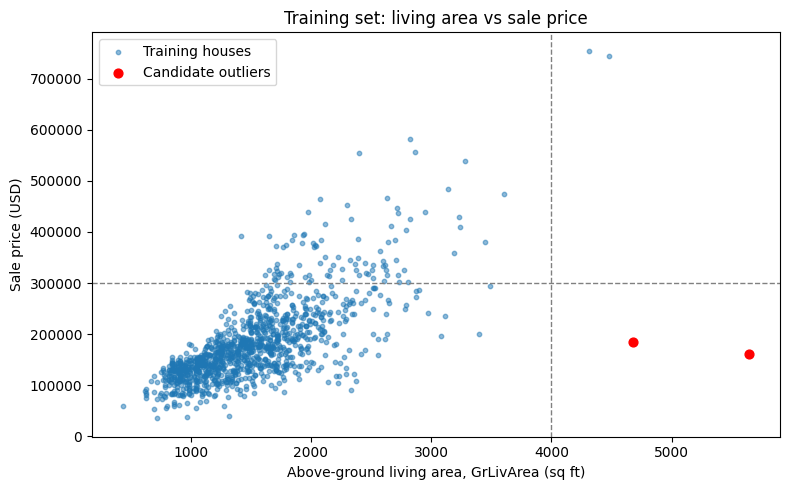

Training houses with GrLivArea > 4000 sq ft: 4
Of these, flagged as outliers           : 2

      GrLivArea SaleCondition  SalePrice (USD)  Flagged
691        4316        Normal         755000.0    False
1182       4476       Abnorml         745000.0    False
523        4676       Partial         184750.0     True
1298       5642       Partial         160000.0     True


In [92]:
# Thresholds from De Cock (2011) and our EDA scatter plot.
OUTLIER_MIN_AREA = 4000      # above-ground living area, sq ft
OUTLIER_MAX_PRICE = 300000   # sale price, USD

# Work in dollars here: the rule is stated in dollars, and dollars are easier to read on a plot.
train_price = np.expm1(y_train)

# A candidate outlier is very large AND cheap: it breaks the "bigger house -> higher price" trend.
is_outlier = (X_train["GrLivArea"] > OUTLIER_MIN_AREA) & (train_price < OUTLIER_MAX_PRICE)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train.loc[~is_outlier, "GrLivArea"], train_price[~is_outlier],
           s=10, alpha=0.5, label="Training houses")
ax.scatter(X_train.loc[is_outlier, "GrLivArea"], train_price[is_outlier],
           s=40, color="red", label="Candidate outliers")
# Dashed lines mark the two thresholds of the rule.
ax.axvline(OUTLIER_MIN_AREA, color="grey", linestyle="--", linewidth=1)
ax.axhline(OUTLIER_MAX_PRICE, color="grey", linestyle="--", linewidth=1)
ax.set_title("Training set: living area vs sale price")
ax.set_xlabel("Above-ground living area, GrLivArea (sq ft)")
ax.set_ylabel("Sale price (USD)")
ax.legend()
fig.tight_layout()
fig.savefig("outputs/figures/train_grlivarea_vs_saleprice.png", dpi=150)
plt.show()

# Show the flagged houses, and every large house, so the rule can be judged house by house.
large_houses = X_train.loc[X_train["GrLivArea"] > OUTLIER_MIN_AREA, ["GrLivArea", "SaleCondition"]].copy()
large_houses["SalePrice (USD)"] = train_price[large_houses.index].round(0)
large_houses["Flagged"] = is_outlier[large_houses.index]
print("Training houses with GrLivArea > 4000 sq ft:", len(large_houses))
print("Of these, flagged as outliers           :", int(is_outlier.sum()))
print()
print(large_houses.sort_values("GrLivArea"))

**Result:** 4 training houses have more than 4,000 sq ft of living area, and 2 of them are flagged.

| Row | GrLivArea (sq ft) | SaleCondition | SalePrice (USD) | Flagged |
|---|---|---|---|---|
| 691 | 4,316 | Normal | 755,000 | No |
| 1182 | 4,476 | Abnorml | 745,000 | No |
| 523 | 4,676 | Partial | 184,750 | Yes |
| 1298 | 5,642 | Partial | 160,000 | Yes |

- Both flagged houses are **partial sales** (sold before construction was finished). This matches De Cock's (2011) explanation: their prices do not reflect market value. Row labels 523 and 1298 are Kaggle `Id`s 524 and 1299, because `Id` = row number + 1.
- The two unflagged large houses sold for \$745,000 or more, so they follow the "bigger house → higher price" trend and are kept. House 1182 is an `Abnorml` sale but is kept anyway: the rule removes houses whose price does not fit their size, not houses with a particular label.
- There is a wide gap between the flagged prices (≤ \$184,750) and the other large houses (≥ \$745,000). Any price threshold inside that gap flags the same two houses, so the result does not depend on the exact choice of \$300,000.
- Both flagged houses are in the training set, so the rule removes them from training. The test set is not filtered.

### 3b. Remove the confirmed outliers from the training set

**What:** drops the 2 flagged houses from `X_train` and `y_train`.

**Why:** the rule was confirmed after looking at the plot and table above. Features and target are filtered with the same row labels, so each remaining house keeps its own price. `X_test` and `y_test` are not touched.

**What to look for:** training set 1,168 → 1,166 houses; the test set still has 292; the feature rows and target values still line up.

In [93]:
def remove_rows(X, y, row_labels):
    """Drop the given rows from both the features and the target.

    Inputs:  X (feature DataFrame), y (target Series), row_labels (index labels to drop).
    Outputs: filtered X and y, still aligned row by row.
    errors="ignore" makes the cell safe to re-run: rows already removed are skipped.
    """
    return X.drop(index=row_labels, errors="ignore"), y.drop(index=row_labels, errors="ignore")


# Take the labels from the mask itself, so this cell does not depend on X_train's current size.
outlier_labels = is_outlier.index[is_outlier]

print("Training set before:", X_train.shape)
X_train, y_train = remove_rows(X_train, y_train, outlier_labels)
print("Training set after :", X_train.shape)
print("Test set (unchanged):", X_test.shape)
print("Removed rows (Kaggle Id):", [int(label) + 1 for label in outlier_labels])
# Features and target must describe the same houses in the same order.
print("X_train and y_train aligned:", X_train.index.equals(y_train.index))

Training set before: (1168, 79)
Training set after : (1166, 79)
Test set (unchanged): (292, 79)
Removed rows (Kaggle Id): [524, 1299]
X_train and y_train aligned: True


## 4. Preprocessing

### 4a. Missing values: a custom imputation transformer

**What:** fills every missing value using the rules decided in EDA:

| Column(s) | Rule | Why |
|---|---|---|
| `PoolQC, MiscFeature, Alley, Fence, FireplaceQu, MasVnrType`, garage and basement categories | the text `"None"` | In this dataset, `NA` means the house **has no** pool, garage, basement, etc. That is real information, not unknown data. |
| `MasVnrArea` | `0` | No masonry veneer means zero veneer area. |
| `LotFrontage` (259 missing) | median of the **same neighbourhood** | Genuinely unknown. Lot widths are similar within a neighbourhood, so the local median is a better guess than the overall median. |
| `Electrical` (1 missing) | most common value (**mode**) | Genuinely unknown; every house has an electrical system. |
| `BsmtExposure`, `BsmtFinType2` for the one house that **has** a basement | mode | This house has a basement, so `"None"` would be wrong. (38 missing vs 37 for the other basement columns.) |
| `GarageYrBlt` | drop the column | 81 missing, and almost always the same year as `YearBuilt`. |

**Why a transformer (a class with `fit` and `transform`):** the neighbourhood medians and the modes are **statistics learned from data**. `fit` learns them from the training set only, and `transform` applies the same values to any data (training, CV folds, test). Later, this transformer goes inside a scikit-learn `Pipeline`. During cross-validation, the pipeline then refits it on each training fold, so no statistic is ever learned from the houses it is evaluated on. This prevents data leakage.

**Why the basement fix comes first:** if every missing basement value were filled with `"None"` first, we could no longer tell the one house that does have a basement apart from the 37 that do not.

In [94]:
# Columns where NA means "the house does not have this feature" (decided in EDA).
NONE_COLS = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "MasVnrType",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
]
# Basement columns with one extra missing value (38 vs 37): a house that HAS a basement.
BSMT_MODE_COLS = ["BsmtExposure", "BsmtFinType2"]


class AmesImputer(BaseEstimator, TransformerMixin):
    """Fill missing values in the Ames data using the rules decided in EDA.

    fit(X):       learns the neighbourhood LotFrontage medians and the modes, from X only.
    transform(X): returns a copy of X with GarageYrBlt dropped and no missing values
                  in the columns listed above.
    """

    def fit(self, X, y=None):
        # mode() ignores missing values, so these are the most common recorded values.
        self.bsmt_modes_ = {col: X[col].mode()[0] for col in BSMT_MODE_COLS}
        self.electrical_mode_ = X["Electrical"].mode()[0]
        self.lot_frontage_by_nbhd_ = X.groupby("Neighborhood")["LotFrontage"].median()
        # Fallback for a neighbourhood with no known LotFrontage in the training data.
        self.lot_frontage_overall_ = X["LotFrontage"].median()
        return self

    def transform(self, X):
        X = X.copy()  # never change the DataFrame passed in

        # 81 missing and nearly identical to YearBuilt, so it adds little information.
        X = X.drop(columns="GarageYrBlt")

        # Must run before the "None" fill: a house with a basement (BsmtQual recorded)
        # but a missing BsmtExposure/BsmtFinType2 gets the mode, not "None".
        has_basement = X["BsmtQual"].notna()
        for col, mode in self.bsmt_modes_.items():
            X.loc[has_basement & X[col].isna(), col] = mode

        X[NONE_COLS] = X[NONE_COLS].fillna("None")
        X["MasVnrArea"] = X["MasVnrArea"].fillna(0)  # no veneer -> zero area

        # Each house gets its neighbourhood's training median; unseen/empty neighbourhoods
        # fall back to the overall training median.
        nbhd_median = X["Neighborhood"].map(self.lot_frontage_by_nbhd_)
        X["LotFrontage"] = X["LotFrontage"].fillna(nbhd_median).fillna(self.lot_frontage_overall_)

        X["Electrical"] = X["Electrical"].fillna(self.electrical_mode_)
        return X

**Check the imputer.** This cell fits the imputer on the training set and applies it to both sets, only to check that it works. In the final pipeline this happens inside the `Pipeline`, so the transformed copies made here are not used for modelling.

**What to look for:**
- 0 missing values left in both the training and test sets. If the test set still has some, a column there has missing values that the training set did not, and we need a rule for it.
- 78 columns (79 minus `GarageYrBlt`).
- The learned statistics (modes, medians) look sensible.
- `X_train` itself still has its missing values, which shows the transformer works on a copy.

In [95]:
imputer = AmesImputer()
imputer.fit(X_train)  # statistics learned from the training set only
X_train_imp = imputer.transform(X_train)
X_test_imp = imputer.transform(X_test)

print("Missing values before (train):", int(X_train.isna().sum().sum()))
print("Missing values after  (train):", int(X_train_imp.isna().sum().sum()))
print("Missing values after  (test) :", int(X_test_imp.isna().sum().sum()))
print("Columns after imputation     :", X_train_imp.shape[1])
print("X_train still unchanged      :", X_train.isna().any().any())

print("\nLearned from the training set:")
print("  Electrical mode           :", imputer.electrical_mode_)
print("  Basement modes            :", imputer.bsmt_modes_)
print("  LotFrontage overall median:", imputer.lot_frontage_overall_, "ft")
print("  LotFrontage median by neighbourhood (ft), first 5:")
print(imputer.lot_frontage_by_nbhd_.head().round(1).to_string())

Missing values before (train): 6267
Missing values after  (train): 0
Missing values after  (test) : 0
Columns after imputation     : 78
X_train still unchanged      : True

Learned from the training set:
  Electrical mode           : SBrkr
  Basement modes            : {'BsmtExposure': 'No', 'BsmtFinType2': 'Unf'}
  LotFrontage overall median: 70.0 ft
  LotFrontage median by neighbourhood (ft), first 5:
Neighborhood
Blmngtn    43.0
Blueste    24.0
BrDale     21.0
BrkSide    52.0
ClearCr    80.0


**Result:** the imputer filled all 6,267 missing values in the training set and left 0 in the test set. So the rules cover every column with gaps, including in houses the imputer did not learn from. 78 columns remain (only `GarageYrBlt` was dropped), and `X_train` itself was not modified.

Values learned from the training set:
- **`Electrical` → `SBrkr`** (standard circuit breakers), the most common wiring type.
- **`BsmtExposure` → `No`** for the house that has a basement. `No` is a real category meaning "a basement with no walkout or garden-level walls", which is different from `"None"` (no basement at all). This is why the basement fix runs before the `"None"` fill.
- **`BsmtFinType2` → `Unf`** (unfinished basement area).
- **`LotFrontage`:** the overall training median is 70 ft, but the neighbourhood medians differ a lot. Among just the first five neighbourhoods alphabetically they range from 21 ft (BrDale) to 80 ft (ClearCr). With a single overall median, a BrDale house would get 70 ft, more than three times its neighbourhood's typical lot width. This supports filling by neighbourhood.

### 4b. Quality columns: ordinal encoding

**What:** converts the 10 quality and condition columns from text grades to numbers that keep their order:

| Grade | `None` | `Po` (Poor) | `Fa` (Fair) | `TA` (Typical/Average) | `Gd` (Good) | `Ex` (Excellent) |
|---|---|---|---|---|---|---|
| Number | 0 | 1 | 2 | 3 | 4 | 5 |

Columns: `ExterQual, ExterCond, BsmtQual, BsmtCond, HeatingQC, KitchenQual, FireplaceQu, GarageQual, GarageCond, PoolQC`.

**Why ordinal and not one-hot:** these grades have a natural order (Poor < Fair < ... < Excellent). One number per column keeps that order, so a model can learn "better kitchen → higher price" directly. One-hot encoding would split each column into up to 6 unrelated 0/1 columns and throw the order away.

**Assumption to be aware of:** a linear model treats the steps as equal: Fair → Typical counts as much as Good → Excellent. This is a simplification. Tree models (Random Forest, XGBoost) only use the order, not the spacing, so it does not affect them.

**Why a transformer:** there is nothing to learn here (the mapping is fixed), but as a transformer it sits in the same `Pipeline` as the imputer and is applied identically to every CV fold and to the test set. It runs **after** the imputer, which has already turned missing values into `"None"`.

**What to look for:** all 10 columns become numbers (`int64`), with no missing values. In the `KitchenQual` cross-table, each grade should appear under exactly one number (e.g. every `Gd` under `4`).

In [96]:
# Ordered quality grades used throughout the Ames data documentation.
QUALITY_MAP = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
QUALITY_COLS = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
    "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC",
]


class QualityEncoder(BaseEstimator, TransformerMixin):
    """Map quality grades (None/Po/Fa/TA/Gd/Ex) to 0-5 in the quality columns.

    fit(X):       nothing to learn (the mapping is fixed); returns self.
    transform(X): returns a copy of X with QUALITY_COLS as integers 0-5.
    Must run after AmesImputer, so missing values are already "None".
    """

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for col in QUALITY_COLS:
            mapped = X[col].map(QUALITY_MAP)
            # A grade outside the map would silently become NaN; stop with a clear message instead.
            unknown = X.loc[mapped.isna(), col].unique()
            if len(unknown) > 0:
                raise ValueError(f"Unexpected grade(s) in {col}: {list(unknown)}")
            X[col] = mapped.astype("int64")
        return X

In [97]:
# Check: apply to the imputed copies from 4a (for checking only; the Pipeline does this later).
quality_encoder = QualityEncoder()
X_train_q = quality_encoder.fit_transform(X_train_imp)
X_test_q = quality_encoder.transform(X_test_imp)

print("Quality column dtypes (train):", sorted(X_train_q[QUALITY_COLS].dtypes.astype(str).unique()))
print("Missing in quality columns (train):", int(X_train_q[QUALITY_COLS].isna().sum().sum()))
print("Missing in quality columns (test) :", int(X_test_q[QUALITY_COLS].isna().sum().sum()))

# Cross-table for one column: rows = original grade, columns = new number.
# Each row should have exactly one non-zero cell, under the number from QUALITY_MAP.
print("\nKitchenQual, training set (rows = grade before, columns = number after):")
print(pd.crosstab(X_train_imp["KitchenQual"], X_train_q["KitchenQual"]))

Quality column dtypes (train): ['int64']
Missing in quality columns (train): 0
Missing in quality columns (test) : 0

KitchenQual, training set (rows = grade before, columns = number after):
KitchenQual   2    3    4   5
KitchenQual                  
Ex            0    0    0  81
Fa           31    0    0   0
Gd            0    0  458   0
TA            0  596    0   0


**Result:** all 10 quality columns are now integers (`int64`), with 0 missing values in both the training and test sets.

The `KitchenQual` cross-table shows each grade under exactly one number: `Fa` → 2 (31 houses), `TA` → 3 (596), `Gd` → 4 (458), `Ex` → 5 (81). These add up to 1,166, the size of the training set after outlier removal, so no house was lost or changed.

No training house has a `Po` or `None` kitchen, so 0 and 1 do not appear for this column. This is not a problem: the mapping is fixed, not learned from the data, so a test house with a `Po` kitchen would still correctly become 1. (Pandas lists the rows alphabetically, Ex/Fa/Gd/TA, which is not the quality order. It does not affect the mapping.)

### 4c. One-hot encoding, scaling, and the full preprocessing pipeline

**What:** after imputation and quality encoding, every column is either a **number** or **text**. A `ColumnTransformer` treats the two groups differently:
- **Text (categorical) columns** (`Neighborhood`, `MSZoning`, `MSSubClass`, ...) → **one-hot encoding**: one 0/1 column per category, e.g. `Neighborhood_CollgCr = 1` for houses in College Creek.
- **Numeric columns** (areas, years, counts, the 0–5 quality grades) → **`StandardScaler`**: subtract the training mean and divide by the training standard deviation, so every column has mean 0 and standard deviation 1.

Finally, the three steps are chained into one `Pipeline`: `AmesImputer` → `QualityEncoder` → `ColumnTransformer`.

**Why one-hot:** models need numbers. Unlike the quality grades, categories such as neighbourhoods have no order, so giving them 1, 2, 3, ... would invent one. One-hot avoids that.
- `handle_unknown="ignore"`: if a test house (or a CV fold) has a category that was not in the training data, it gets all zeros instead of crashing the pipeline.

**Why scale:** Ridge and Lasso penalise large coefficients. Without scaling, the penalty would hit a feature measured in small numbers (e.g. bathrooms, 0–3) much harder than one measured in large numbers (e.g. lot area, thousands of sq ft), purely because of the units. Scaling puts every numeric feature on the same footing. Tree models do not need it, but it does them no harm.

**Why columns are chosen by type, not by name:** `make_column_selector` picks columns by data type when the pipeline is fitted. The engineered features from Step 5 (e.g. `TotalSF`) will be numbers, so they are scaled automatically without editing a column list.

**Why one `Pipeline`:** in cross-validation, the whole pipeline is refitted on each fold's training part. Imputation statistics, the list of categories and the scaling means are all learned without seeing the fold being scored. This prevents data leakage.

**Note on plain Linear Regression:** with every category kept, the one-hot columns of each feature always add up to 1, which duplicates the model's intercept (**perfect multicollinearity**). scikit-learn's `LinearRegression` still finds a solution and its predictions are valid, but its individual one-hot coefficients are not unique, so we do not interpret them. Ridge and Lasso are not affected, because the penalty makes their solution unique.

**What to look for:** the same number of columns for train and test; 0 missing values; scaled numeric columns with training means ≈ 0 and standard deviations ≈ 1 (on the test set only close, not exact, because the scaler learned from the training set); and a count of test categories that never appear in training. Those are the ones `handle_unknown="ignore"` deals with.

In [98]:
class DropColumns(BaseEstimator, TransformerMixin):
    """Drop the given columns (used by the location ablation in Section 11).

    fit(X):       nothing to learn; returns self.
    transform(X): returns a copy of X without `columns`.
    """

    def __init__(self, columns=()):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.drop(columns=list(self.columns))


LOCATION_OPTIONS = ("onehot", "none", "target")


def build_preprocessor(add_features=True, location="onehot"):
    """Build an unfitted preprocessing pipeline.

    Steps: AmesImputer -> QualityEncoder -> [FeatureEngineer] -> [DropColumns] -> ColumnTransformer
           (StandardScaler on numeric columns, OneHotEncoder on text columns).
    Inputs: add_features - include the engineered features from Section 5 (default True).
                           Set to False only to inspect preprocessing on its own, as in the 4c check below.
            location     - how Neighborhood is used (Section 11 ablation):
                           "onehot" (default, used by all models in Section 7): one-hot like other text columns;
                           "none":   Neighborhood dropped (after imputation, which still uses it for LotFrontage);
                           "target": Neighborhood target-encoded (Tier 1), then scaled.
    Output: a scikit-learn Pipeline whose transform returns a pandas DataFrame of numbers.
    A fresh, unfitted pipeline is built each time, so different models never share fitted state.
    """
    if location not in LOCATION_OPTIONS:
        raise ValueError(f"location must be one of {LOCATION_OPTIONS}, got {location!r}")

    # Columns are chosen by type when fitted, so the engineered numeric features are included.
    transformers = [("num", StandardScaler(), make_column_selector(dtype_include="number"))]
    if location == "target":
        # TargetEncoder replaces each neighbourhood with the mean log price of its training houses.
        # It cross-fits internally (each training house is encoded using the other folds only),
        # so a house's own price never leaks into its own encoding.
        transformers += [
            ("nbhd", Pipeline([
                ("target_encode", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE)),
                ("scale", StandardScaler()),
            ]), ["Neighborhood"]),
            # All other text columns are still one-hot encoded (regex: every column except Neighborhood).
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
             make_column_selector(dtype_include=object, pattern="^(?!Neighborhood$)")),
        ]
    else:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                             make_column_selector(dtype_include=object)))
    encode_and_scale = ColumnTransformer(transformers=transformers)
    # Return a DataFrame with column names ("num__GrLivArea", "cat__Neighborhood_CollgCr", ...),
    # which we need later to label coefficients and SHAP plots.
    encode_and_scale.set_output(transform="pandas")

    steps = [("impute", AmesImputer()), ("quality", QualityEncoder())]
    if add_features:
        # FeatureEngineer is defined in Section 5; it only needs to exist when this function is called.
        steps.append(("features", FeatureEngineer()))
    if location == "none":
        steps.append(("drop_location", DropColumns(["Neighborhood"])))
    steps.append(("encode_scale", encode_and_scale))
    return Pipeline(steps)

In [99]:
# Check: fit the whole preprocessing pipeline on the training set only, then apply it to both sets.
# add_features=False: the engineered features are added and checked separately in Section 5.
preprocessor = build_preprocessor(add_features=False)
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

num_cols = [c for c in X_train_prep.columns if c.startswith("num__")]
cat_cols = [c for c in X_train_prep.columns if c.startswith("cat__")]
print("Raw feature columns       :", X_train.shape[1])
print("Train after preprocessing :", X_train_prep.shape)
print("Test after preprocessing  :", X_test_prep.shape)
print("  scaled numeric columns  :", len(num_cols))
print("  one-hot columns         :", len(cat_cols))
print("Missing values (train/test):", int(X_train_prep.isna().sum().sum()), "/", int(X_test_prep.isna().sum().sum()))

# ddof=0 matches how StandardScaler computes the standard deviation.
for name, data in [("train", X_train_prep), ("test", X_test_prep)]:
    means = data[num_cols].mean()
    stds = data[num_cols].std(ddof=0)
    print(f"Scaled numeric ({name}): means {means.min():.3f} to {means.max():.3f}, "
          f"std devs {stds.min():.3f} to {stds.max():.3f}")

# Name the test-set extremes, so differences from the training set can be explained.
test_stds = X_test_prep[num_cols].std(ddof=0)
constant_in_test = test_stds[test_stds == 0].index.tolist()
print("\nNumeric columns constant in the test set :", constant_in_test)
print("Numeric column with the largest test std :", test_stds.idxmax(), round(test_stds.max(), 3))

# Categories in the test set that never occur in the training set (handled by handle_unknown="ignore").
# Uses the imputed + quality-encoded copies from 4b, i.e. exactly what the one-hot encoder receives.
text_cols = X_train_q.select_dtypes(include=object).columns
print("\nTest categories never seen in training (column: categories, test houses affected):")
for col in text_cols:
    unseen_cats = sorted(set(X_test_q[col]) - set(X_train_q[col]))
    if unseen_cats:
        n_houses = int(X_test_q[col].isin(unseen_cats).sum())
        print(f"  {col}: {unseen_cats}, {n_houses} house(s)")

Raw feature columns       : 79
Train after preprocessing : (1166, 272)
Test after preprocessing  : (292, 272)
  scaled numeric columns  : 44
  one-hot columns         : 228
Missing values (train/test): 0 / 0
Scaled numeric (train): means -0.000 to 0.000, std devs 1.000 to 1.000
Scaled numeric (test): means -0.087 to 0.173, std devs 0.000 to 1.535

Numeric columns constant in the test set : ['num__PoolQC']
Numeric column with the largest test std : num__LotArea 1.535

Test categories never seen in training (column: categories, test houses affected):
  Utilities: ['NoSeWa'], 1 house(s)
  Functional: ['Sev'], 1 house(s)


**Result:** the full preprocessing pipeline turns the 79 raw features into **272 numeric columns**, with the same columns for the training set (1,166 houses) and the test set (292 houses), and 0 missing values in either.
- 79 → 78 after dropping `GarageYrBlt`. Of those 78, the **44 numeric columns** (including the 10 quality grades) are scaled. The **34 text columns** become **228 one-hot columns**. 44 + 228 = 272.
- **Training set:** every scaled numeric column has mean 0.000 and standard deviation 1.000, as expected. No numeric column is constant in the training set.
- **Test set:** means range from −0.087 to 0.173 and standard deviations from 0.000 to 1.535. They are close to 0 and 1 but not exact, because the scaler learned from the training set only. An exact match on the test set would suggest leakage.
  - `PoolQC` is constant in the test set: every test house has grade 0 (no pool). Pools are rare, so with 292 houses this is plausible. The feature cannot influence any test prediction.
  - `LotArea` has the largest test spread (1.535 training standard deviations): test lot areas vary more than training ones.
- **Unseen categories:** two test categories never appear in training: `Utilities = NoSeWa` (1 test house) and `Functional = Sev` (1 test house). These may be the same house or two different ones. Thanks to `handle_unknown="ignore"`, that feature's one-hot columns are all zeros for the affected house instead of crashing the pipeline. At most 2 of 292 test houses are affected, so the effect on the test score is small.

## 5. Feature engineering

**What:** adds five new numeric features built from existing columns:

| New feature | Formula | Why it can help |
|---|---|---|
| `TotalSF` | `TotalBsmtSF + 1stFlrSF + 2ndFlrSF` | Buyers pay for total floor space. One combined size measure is easier for a model to use than three separate parts. |
| `TotalBath` | `FullBath + 0.5·HalfBath + BsmtFullBath + 0.5·BsmtHalfBath` | Total bathrooms in one number. A half bath (toilet and sink, no shower) counts as half, the usual real-estate convention. |
| `HouseAge` | `YrSold − YearBuilt` | The age at the time of sale matters more than the build year itself. A 1990 house sold in 2006 or in 2010 is a different age. |
| `YearsSinceRemod` | `YrSold − YearRemodAdd` | How recently the house was renovated, at the time of sale (equals `HouseAge` if never remodelled). |
| `QualxSize` | `OverallQual × GrLivArea` | An **interaction**: an extra square foot is worth more in a high-quality house than in a poor one. A linear model cannot create this product by itself, so we give it directly. |

**Why keep the original columns too:** the new features overlap with the columns they are built from (e.g. `TotalSF` and `TotalBsmtSF`). As decided in EDA, we keep both. Ridge and Lasso handle the overlap (multicollinearity), and Lasso can drop columns that add nothing. Whether the new features actually help will show up in the CV scores.

**Why a transformer:** like the quality encoder, it learns nothing (fixed formulas), but it sits in the `Pipeline` between `QualityEncoder` and the `ColumnTransformer`. So the new features are created for every CV fold and the test set in the same way, and then scaled automatically because they are numeric.

**What to look for:**
- Sensible ranges (e.g. no negative areas).
- Whether any `HouseAge` or `YearsSinceRemod` values are **negative**, which would mean the year sold is before the year built or remodelled. This can happen with houses sold before construction finished.
- How strongly each new feature correlates with log price, compared with its strongest ingredient.
- The pipeline output growing from 272 to 277 columns.

In [100]:
ENGINEERED_COLS = ["TotalSF", "TotalBath", "HouseAge", "YearsSinceRemod", "QualxSize"]
HALF_BATH_WEIGHT = 0.5  # a half bath (toilet + sink, no shower) counts as half a bathroom


class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Add five engineered numeric features (see the table above).

    fit(X):       nothing to learn (fixed formulas); returns self.
    transform(X): returns a copy of X with ENGINEERED_COLS added; original columns are kept.
    """

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["TotalSF"] = X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"]
        X["TotalBath"] = (X["FullBath"] + HALF_BATH_WEIGHT * X["HalfBath"]
                          + X["BsmtFullBath"] + HALF_BATH_WEIGHT * X["BsmtHalfBath"])
        # Ages are measured at the time of sale, so houses sold in different years are comparable.
        X["HouseAge"] = X["YrSold"] - X["YearBuilt"]
        X["YearsSinceRemod"] = X["YrSold"] - X["YearRemodAdd"]
        # Interaction: lets a linear model price a square foot differently by quality level.
        X["QualxSize"] = X["OverallQual"] * X["GrLivArea"]
        return X

In [101]:
# Check 1: the new features on the training set (imputed + quality-encoded copy from 4b), before scaling.
X_train_fe = FeatureEngineer().fit_transform(X_train_q)

print("Engineered features, training set (before scaling):")
print(X_train_fe[ENGINEERED_COLS].describe().loc[["min", "mean", "max"]].T.round(1))

for col in ["HouseAge", "YearsSinceRemod"]:
    print(f"Negative {col} values (train):", int((X_train_fe[col] < 0).sum()))

# Check 2: does each new feature track log price better than its strongest ingredient?
# Training set only; this is a sanity check, the real test is the CV score in Section 7.
INGREDIENTS = {
    "TotalSF": ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"],
    "TotalBath": ["FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath"],
    "HouseAge": ["YrSold", "YearBuilt"],
    "YearsSinceRemod": ["YrSold", "YearRemodAdd"],
    "QualxSize": ["OverallQual", "GrLivArea"],
}
rows = []
for new_col, parts in INGREDIENTS.items():
    part_corrs = X_train_fe[parts].corrwith(y_train)
    best_part = part_corrs.abs().idxmax()  # strongest ingredient, ignoring the sign
    rows.append({
        "new feature": new_col,
        "corr with log price": X_train_fe[new_col].corr(y_train),
        "strongest ingredient": best_part,
        "ingredient corr": part_corrs[best_part],
    })
print("\nCorrelation with log price (training set):")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Check 3: the full pipeline, now with the engineered features included (the default).
full_preprocessor = build_preprocessor()
X_train_full = full_preprocessor.fit_transform(X_train)
X_test_full = full_preprocessor.transform(X_test)
print("\nFull pipeline output (train / test):", X_train_full.shape, "/", X_test_full.shape)
print("Engineered columns present        :", all(f"num__{c}" in X_train_full.columns for c in ENGINEERED_COLS))
print("Missing values (train / test)     :", int(X_train_full.isna().sum().sum()), "/", int(X_test_full.isna().sum().sum()))

Engineered features, training set (before scaling):
                   min    mean      max
TotalSF          720.0  2559.9   6872.0
TotalBath          1.0     2.2      5.0
HouseAge           0.0    36.7    136.0
YearsSinceRemod    0.0    23.2     60.0
QualxSize        876.0  9638.6  44760.0
Negative HouseAge values (train): 0
Negative YearsSinceRemod values (train): 0

Correlation with log price (training set):
    new feature  corr with log price strongest ingredient  ingredient corr
        TotalSF                0.821          TotalBsmtSF            0.641
      TotalBath                0.687             FullBath            0.582
       HouseAge               -0.581            YearBuilt            0.581
YearsSinceRemod               -0.578         YearRemodAdd            0.576
      QualxSize                0.834          OverallQual            0.819

Full pipeline output (train / test): (1166, 277) / (292, 277)
Engineered columns present        : True
Missing values (train / test)  

**Result:**

**Ranges (training set, before scaling) are all plausible.** `TotalSF` runs from 720 to 6,872 sq ft (mean 2,560), `TotalBath` from 1 to 5 (mean 2.2), `HouseAge` from 0 to 136 years (mean 36.7), `YearsSinceRemod` from 0 to 60 years (mean 23.2), and `QualxSize` from 876 to 44,760. There are no negative ages: no training house was sold before it was built or remodelled.

**Correlation with log price, compared with each feature's strongest ingredient (training set):**

| New feature | Corr. with log price | Strongest ingredient | Ingredient corr. |
|---|---|---|---|
| `TotalSF` | 0.821 | `TotalBsmtSF` | 0.641 |
| `TotalBath` | 0.687 | `FullBath` | 0.582 |
| `QualxSize` | 0.834 | `OverallQual` | 0.819 |
| `HouseAge` | −0.581 | `YearBuilt` | 0.581 |
| `YearsSinceRemod` | −0.578 | `YearRemodAdd` | 0.576 |

- `TotalSF` and `TotalBath` follow log price clearly more closely than any of their parts. Combining the parts adds information.
- `QualxSize` is slightly stronger than `OverallQual`, its strongest ingredient.
- `HouseAge` and `YearsSinceRemod` are almost exact mirror images of `YearBuilt` and `YearRemodAdd`: the same strength with the opposite sign. This is because `YrSold` only covers a few years, so subtracting the build year from it mostly just flips the sign. These two features make the data easier to read (age in years) but add little new information.
- Caveat: each feature is compared only with its own ingredients. `GrLivArea` is not an ingredient of `TotalSF`, so this table does not show how `TotalSF` compares with the strongest existing size column.

Correlation measures only a straight-line relationship with one feature at a time, so it is a hint, not proof. Whether these features improve prediction is decided by the cross-validated RMSE in Section 7.

**Pipeline:** with the features included, the full preprocessing pipeline outputs **277 columns** (272 + 5) for both the training and test sets, all five engineered columns are present, and there are 0 missing values.

## 7. Models, evaluated with 5-fold cross-validation on the training set

*(Section 6, location features, is added later for the ablation in Section 11.)*

### 7a. A shared cross-validation helper

**What:** one function, `evaluate_cv`, that every model goes through. It:
1. wraps the model in a full pipeline: `build_preprocessor()` → model;
2. runs **5-fold cross-validation** on the training set: the 1,166 training houses are split into 5 parts (**folds**). The pipeline is trained 5 times, each time on 4 folds and scored on the 5th, so every house is used for scoring exactly once;
3. reports, averaged over the 5 runs:
   - **train RMSE**: error on the 4 folds the model was trained on;
   - **CV RMSE** (mean ± standard deviation): error on the held-out fold. This estimates how well the model predicts houses it has not seen.

**Why RMSE on log price:** **RMSE** (root mean squared error) is the square root of the average squared difference between predicted and actual values. On log price, an error of 0.10 means a prediction about 10% too high or too low, whatever the price level. A \$20,000 miss on a \$100,000 house therefore counts more than on a \$500,000 house. It is also the Kaggle competition's metric.

**Why cross-validation, not one validation split:** with only 1,166 houses, a single 20% validation split would give a score that depends heavily on which houses happen to land in it. Averaging 5 folds is more stable, and the standard deviation shows how much the score varies between folds. These 5 folds are the **validation** step the brief asks for. The test set is still untouched.

**Why train RMSE as well:** comparing it with CV RMSE shows the **bias–variance** picture (Section 8):
- both high → **underfitting** (the model is too simple);
- train RMSE much lower than CV RMSE → **overfitting** (the model memorises the training houses).

**Why the whole pipeline goes inside CV:** preprocessing is refitted on the 4 training folds every time, so the held-out fold never influences the medians, categories or scaling. This prevents leakage inside CV.

The folds are shuffled with `random_state=42`, and the **same** `KFold` object is used for every model. So all models are scored on identical folds, which keeps the comparison fair.

In [102]:
N_FOLDS = 5  # the brief's validation step; 5 folds of ~233 houses each
# One shared KFold object: every model is scored on exactly the same folds (fair comparison).
CV = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Collected results, keyed by model name, so re-running a model's cell replaces its row
# instead of adding a duplicate. Saved to outputs/results/cv_results.csv in Section 8.
cv_summary = {}


def make_model_pipeline(model):
    """Return an unfitted Pipeline: fresh preprocessing (Sections 4-5) followed by `model`."""
    return Pipeline([("prep", build_preprocessor()), ("model", model)])


def evaluate_cv(name, model, X, y):
    """Run 5-fold CV of preprocessing + model on the training data.

    Inputs:  name (label for the results table), model (unfitted scikit-learn regressor),
             X, y (training features and log-price target).
    Output:  dict with mean train RMSE, mean and std of CV RMSE, and the train-CV gap.
             The dict is also stored in cv_summary[name] and printed.
    """
    scores = cross_validate(
        make_model_pipeline(model), X, y,
        cv=CV,
        scoring="neg_root_mean_squared_error",  # scikit-learn maximises scores, so RMSE is negated
        return_train_score=True,                # needed for the train vs CV (bias-variance) comparison
    )
    train_rmse = -scores["train_score"]
    cv_rmse = -scores["test_score"]
    result = {
        "model": name,
        "train RMSE": train_rmse.mean(),
        "CV RMSE": cv_rmse.mean(),
        "CV RMSE std": cv_rmse.std(),
        "gap (CV - train)": cv_rmse.mean() - train_rmse.mean(),
    }
    cv_summary[name] = result

    print(f"{name}")
    print(f"  Train RMSE (log)   : {result['train RMSE']:.4f}")
    print(f"  CV RMSE (log)      : {result['CV RMSE']:.4f} ± {result['CV RMSE std']:.4f}")
    print(f"  CV RMSE per fold   : {np.round(cv_rmse, 4)}")
    return result

### 7b. Model 1: Linear Regression (baseline)

**What:** ordinary least-squares linear regression. It predicts log price as a weighted sum of the preprocessed features, with weights chosen to minimise the squared error on the training data. There are 277 features when fitted on the whole training set, and possibly a few fewer inside a CV fold, if a rare category is missing from that fold's 4 training parts. It has no hyperparameters to tune.

**Why start here:** it is the simplest reasonable model. Every more complex model must beat it to justify its extra complexity. A **baseline** is a simple reference model used for this kind of comparison.

**What to look for:**
- the train RMSE vs CV RMSE gap. With so many features, many of them overlapping (one-hot columns, engineered features built from other columns), an unpenalised linear model may fit the training folds much better than the held-out folds (overfitting);
- the per-fold CV RMSE values. If one fold is far worse than the others, a few houses with unusual or rare category combinations are probably getting extreme predictions. That would be a sign that the model needs regularisation (Ridge and Lasso, next).

In [103]:
# Baseline: no hyperparameters, so no tuning; just 5-fold CV on the training set.
linear_result = evaluate_cv("Linear Regression", LinearRegression(), X_train, y_train)

Linear Regression
  Train RMSE (log)   : 0.0858
  CV RMSE (log)      : 0.1324 ± 0.0100
  CV RMSE per fold   : [0.1415 0.1383 0.1335 0.1131 0.1354]


**Result:**

| | RMSE (log price) |
|---|---|
| Train (mean of 5 folds) | 0.0858 |
| CV (mean ± std of 5 folds) | **0.1324 ± 0.0100** |
| Gap (CV − train) | 0.0466 |
| CV per fold | 0.1415, 0.1383, 0.1335, 0.1131, 0.1354 |

- **Moderate overfitting:** the CV error is about 1.5 times the training error. The unpenalised model fits the houses it was trained on noticeably better than unseen houses, which is expected with this many overlapping features. Regularisation (Ridge, Lasso) is designed to reduce this gap.
- **No fold failed:** the per-fold scores range from 0.113 to 0.142. Despite the one-hot multicollinearity, no fold produced extreme predictions. The problem is a consistent gap, not one unstable fold.
- **In price terms:** an RMSE of 0.1324 on log price corresponds to a factor of e^0.1324 ≈ 1.14, i.e. errors of roughly 14% in a root-mean-square sense. Because large errors are squared, this is not the error of a typical house. Many predictions are closer than this.
- **Baseline to beat:** every later model must reach a CV RMSE below **0.1324** to justify its extra complexity.

### 7c. Model 2: Ridge regression, with `alpha` tuned by cross-validation

**What Ridge is:** linear regression with a penalty. It minimises
squared error + `alpha` × (sum of squared coefficients).
The penalty pulls every coefficient towards zero (**shrinkage**), so no single feature, or group of overlapping features, can get an extreme weight just to fit the training houses more closely. `alpha` sets the strength: `alpha = 0` is plain Linear Regression, and a very large `alpha` shrinks everything towards zero (underfitting).

**Why Ridge suits this data:** many of our features overlap (e.g. `GarageCars`/`GarageArea`, `TotalSF` and its parts, one-hot groups). Ridge spreads the weight across overlapping features instead of giving them large opposite-signed coefficients. This is the multicollinearity handling decided in EDA, and it should shrink the train–CV gap seen in the baseline.

**How `alpha` is chosen (hyperparameter tuning):** `GridSearchCV` tries each candidate `alpha` with the **same 5 folds** as the baseline and picks the one with the lowest mean CV RMSE. Each candidate is still scored only on held-out folds, so the choice does not use the test set. The helper `tune_cv` does this for any model and reports the result in the same format as the baseline. It is reused for Lasso.

**Tuning budget:** every tuned model gets **30 candidate settings** (`N_CANDIDATES`), so the comparison between models is fair. For Ridge, these are 30 `alpha` values spaced evenly on a log scale from 0.01 to 1,000. The best `alpha` could be anywhere across several orders of magnitude, so log spacing covers small and large values equally well.

**What to look for:**
- the best `alpha`, and whether it is at the **edge** of the grid (0.01 or 1,000). If it is, the true best value may lie outside the grid, and the grid should be widened. The helper prints a warning in that case.
- train vs CV RMSE: we expect a smaller gap than the baseline's (0.0466). Train RMSE cannot be lower than the baseline's (0.0858), because plain Linear Regression already has the lowest possible training error. Any penalty can only raise it.
- whether CV RMSE drops below the baseline's 0.1324.

In [104]:
N_CANDIDATES = 30  # tuning budget: every tuned model is scored on 30 candidate settings (same 5 folds)


def plain_params(best_params):
    """Strip the Pipeline's "model__" prefix and turn NumPy numbers into plain Python numbers,
    so parameters print and save cleanly (e.g. 18.87 instead of np.float64(18.87...))."""
    return {k.replace("model__", ""): (v.item() if isinstance(v, np.generic) else v)
            for k, v in best_params.items()}


def report_search(name, search):
    """Store and print the best setting found by a fitted GridSearchCV / RandomizedSearchCV.

    Inputs:  name (label for the results table), search (fitted search object).
    Output:  dict in the same format as evaluate_cv, plus "best params"; also stored in cv_summary.
    """
    res = search.cv_results_
    best = search.best_index_
    # Scores are negated RMSE (scikit-learn maximises), so flip the sign back.
    fold_rmse = np.array([-res[f"split{k}_test_score"][best] for k in range(N_FOLDS)])
    result = {
        "model": name,
        "train RMSE": -res["mean_train_score"][best],
        "CV RMSE": -res["mean_test_score"][best],
        "CV RMSE std": res["std_test_score"][best],
        "gap (CV - train)": res["mean_train_score"][best] - res["mean_test_score"][best],
        "best params": plain_params(search.best_params_),
    }
    cv_summary[name] = result

    # Display floats to 4 significant figures (so small values like 0.000672 stay readable);
    # the stored values keep full precision.
    shown = {k: (float(f"{v:.4g}") if isinstance(v, float) else v) for k, v in result["best params"].items()}
    print(f"{name}")
    print(f"  Best params        : {shown}")
    print(f"  Train RMSE (log)   : {result['train RMSE']:.4f}")
    print(f"  CV RMSE (log)      : {result['CV RMSE']:.4f} ± {result['CV RMSE std']:.4f}")
    print(f"  CV RMSE per fold   : {np.round(fold_rmse, 4)}")
    return result


def warn_if_edge(search, param_grid):
    """Print a warning for each numeric parameter whose best value is the smallest or largest
    candidate: the true optimum may then lie outside the range that was searched.
    Lists containing non-numbers (e.g. max_depth=None) are skipped, since they have no clear edge."""
    for k, values in param_grid.items():
        values = list(values)
        if len(values) <= 2 or not all(isinstance(v, (int, float, np.number)) for v in values):
            continue
        best_value = search.best_params_[f"model__{k}"]
        if best_value in (min(values), max(values)):
            print(f"  WARNING: best {k} = {best_value} is at the edge of the grid; consider widening it.")


def tune_cv(name, model, param_grid, X, y):
    """Grid-search the model's hyperparameters with the shared 5 folds, then report the best.

    Inputs:  name, model (unfitted regressor), param_grid (dict: parameter name -> list of values),
             X, y (training data).
    Output:  the fitted GridSearchCV. Its best pipeline is refitted on all of X, y (used in Section 9).
    """
    search = GridSearchCV(
        make_model_pipeline(model),
        param_grid={f"model__{k}": v for k, v in param_grid.items()},  # route params to the "model" step
        cv=CV,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
    )
    search.fit(X, y)
    report_search(name, search)
    warn_if_edge(search, param_grid)
    return search

In [105]:
# 30 alphas from 0.01 to 1,000, evenly spaced on a log scale (the tuning budget).
RIDGE_ALPHAS = np.logspace(-2, 3, N_CANDIDATES)

ridge_search = tune_cv("Ridge", Ridge(), {"alpha": RIDGE_ALPHAS}, X_train, y_train)

Ridge
  Best params        : {'alpha': 18.87}
  Train RMSE (log)   : 0.0978
  CV RMSE (log)      : 0.1148 ± 0.0131
  CV RMSE per fold   : [0.1255 0.0952 0.1147 0.1065 0.1319]


**Result:**

| | Linear Regression | Ridge (`alpha` ≈ 18.87) |
|---|---|---|
| Train RMSE (log) | 0.0858 | 0.0978 |
| CV RMSE (log) | 0.1324 ± 0.0100 | **0.1148 ± 0.0131** |
| Gap (CV − train) | 0.0466 | 0.0170 |
| CV per fold | 0.1415, 0.1383, 0.1335, 0.1131, 0.1354 | 0.1255, 0.0952, 0.1147, 0.1065, 0.1319 |

- **Regularisation worked as expected.** Train RMSE rose (0.0858 → 0.0978), as it must when a penalty is added. CV RMSE fell (0.1324 → 0.1148), and the train–CV gap shrank to about a third of its size (0.0466 → 0.0170). Ridge accepts a slightly worse fit to the training houses in exchange for clearly better predictions on unseen houses. This is the bias–variance trade-off.
- **Every fold improved.** Both models were scored on the same 5 folds, so they can be compared fold by fold, and Ridge is better on all five. The improvement does not depend on one lucky fold.
- **The best `alpha` (≈ 18.87) lies well inside the grid** (0.01 to 1,000), and no edge warning appeared, so the search range was wide enough.
- The spread across folds is slightly larger than the baseline's (std 0.0131 vs 0.0100), mainly because fold 2 improved much more than the others.
- **New best CV RMSE: 0.1148.**

### 7d. Model 3: Lasso regression, with `alpha` tuned by cross-validation

**What Lasso is:** linear regression with a different penalty. It minimises
squared error + `alpha` × (sum of **absolute** coefficient values).
Like Ridge, it shrinks coefficients. Unlike Ridge, the absolute-value penalty can push coefficients to **exactly zero**, which removes those features from the model. Lasso therefore does **feature selection** automatically: it keeps the features that earn their place and drops the rest.

**Why try it here:** we have 277 overlapping features, and some (e.g. rare one-hot categories, or `HouseAge` next to `YearBuilt`) may add little. If Lasso matches Ridge's accuracy with far fewer features, the model is simpler and easier to explain. CLAUDE.md also asks us to report how many features Lasso zeroes out.

**Grid:** 30 `alpha` values (the same budget as Ridge) from 0.0001 to 1 on a log scale. This range is lower than Ridge's, because Lasso's penalty uses absolute values instead of squares, so its useful `alpha` values sit on a different scale. The edge warning will show if this guess is wrong.

**`max_iter=50000`:** Lasso is solved step by step (**coordinate descent**), and very small `alpha` values with many correlated features can need many steps to converge. If scikit-learn still prints `ConvergenceWarning`s, they come from the smallest `alpha`s. They only matter if one of those `alpha`s ends up being chosen.

**What to look for:**
- best `alpha`, and no edge warning;
- train vs CV RMSE, compared with Ridge (0.0978 / 0.1148);
- in the second cell: how many of the 277 features have a coefficient of exactly 0 in the best model (refitted on the whole training set), which features have the largest coefficients, and whether the engineered features survived.

**How to read the coefficients:** numeric features are scaled, so a coefficient is the change in **log price** for a one-standard-deviation increase in that feature, with all other features held fixed. One-hot coefficients are the change for houses in that category. With overlapping features, individual coefficients should be read with care: Lasso may keep one of two similar features and drop the other more or less arbitrarily.

In [106]:
# 30 alphas from 0.0001 to 1, evenly spaced on a log scale (same budget as Ridge).
LASSO_ALPHAS = np.logspace(-4, 0, N_CANDIDATES)

# max_iter raised from the default 1,000: small alphas with correlated features converge slowly.
lasso_search = tune_cv("Lasso", Lasso(max_iter=50_000), {"alpha": LASSO_ALPHAS}, X_train, y_train)

Lasso
  Best params        : {'alpha': 0.0006723}
  Train RMSE (log)   : 0.0992
  CV RMSE (log)      : 0.1123 ± 0.0122
  CV RMSE per fold   : [0.1252 0.0947 0.1119 0.1036 0.1261]


In [107]:
# Feature selection: inspect the best Lasso, refitted by GridSearchCV on the whole training set.
best_lasso = lasso_search.best_estimator_
feature_names = best_lasso.named_steps["prep"].named_steps["encode_scale"].get_feature_names_out()
lasso_coefs = pd.Series(best_lasso.named_steps["model"].coef_, index=feature_names)

n_zero = int((lasso_coefs == 0).sum())
print("Features in total        :", len(lasso_coefs))
print("Coefficients exactly 0   :", n_zero)
print("Features kept (non-zero) :", len(lasso_coefs) - n_zero)
cv_summary["Lasso"]["features kept"] = len(lasso_coefs) - n_zero  # recorded in cv_results.csv

# Sorted by absolute size: the features with the most influence on predicted log price.
print("\nTop 10 coefficients by size (change in log price per 1 std / for that category):")
top10 = lasso_coefs.reindex(lasso_coefs.abs().sort_values(ascending=False).index).head(10)
print(top10.round(4).to_string())

print("\nEngineered features (0 = dropped by Lasso):")
print(lasso_coefs[[f"num__{c}" for c in ENGINEERED_COLS]].round(4).to_string())

Features in total        : 277
Coefficients exactly 0   : 185
Features kept (non-zero) : 92

Top 10 coefficients by size (change in log price per 1 std / for that category):
cat__MSZoning_C (all)       -0.2395
cat__Neighborhood_Crawfor    0.1233
num__TotalSF                 0.0734
cat__Neighborhood_StoneBr    0.0675
cat__Neighborhood_BrkSide    0.0630
num__OverallQual             0.0579
num__GrLivArea               0.0525
cat__Functional_Typ          0.0520
num__HouseAge               -0.0488
cat__MSZoning_RM            -0.0476

Engineered features (0 = dropped by Lasso):
num__TotalSF            0.0734
num__TotalBath          0.0174
num__HouseAge          -0.0488
num__YearsSinceRemod   -0.0139
num__QualxSize          0.0304


**Result:**

| | Ridge | Lasso (`alpha` ≈ 0.00067) |
|---|---|---|
| Train RMSE (log) | 0.0978 | 0.0992 |
| CV RMSE (log) | 0.1148 ± 0.0131 | **0.1123 ± 0.0122** |
| Gap (CV − train) | 0.0170 | 0.0131 |
| CV per fold | 0.1255, 0.0952, 0.1147, 0.1065, 0.1319 | 0.1252, 0.0947, 0.1119, 0.1036, 0.1261 |
| Features used | all 277 | **92** |

**Accuracy.** Lasso has the lowest CV RMSE so far, and it is better than Ridge on all 5 folds. The improvement is small, though: the mean gain (0.0025) is smaller than the fold-to-fold spread (std ≈ 0.012). So the fair summary is "slightly but consistently better on the same folds", not a large improvement. The best `alpha` lies inside the grid (0.0001 to 1), and no convergence warnings appeared.

**Feature selection.** 185 of the 277 coefficients are exactly 0. Lasso matches Ridge's accuracy using only 92 features, about a third. This makes it a simpler model and easier to explain.

**Largest coefficients** (in the model refitted on the whole training set):
- `TotalSF` (+0.073) is the strongest numeric feature, ahead of `OverallQual` (+0.058) and `GrLivArea` (+0.053). It is one of our engineered features.
- **All five engineered features were kept** (none is 0): `TotalSF` +0.073, `HouseAge` −0.049, `QualxSize` +0.030, `TotalBath` +0.017, `YearsSinceRemod` −0.014. Because overlapping features compete, a kept feature may have "won" over a near-duplicate (e.g. `HouseAge` vs `YearBuilt`). It is not necessarily more important than the one dropped.
- Three neighbourhoods appear in the top 10: Crawfor (+0.123), StoneBr (+0.068), BrkSide (+0.063). Location carries information even with plain one-hot encoding, which is relevant to the location ablation (Section 11).
- The largest coefficient is `MSZoning_C (all)` (commercial zoning, −0.240): such houses are predicted about 21% cheaper (e^−0.24 ≈ 0.79), all else equal.

**Caveats when reading these coefficients:**
1. One-hot coefficients (the effect of being in a category) and scaled numeric coefficients (the effect of one standard deviation more) are on different scales, so the top-10 list mixes two kinds of number.
2. A rare category can get a large coefficient from only a few houses. The number of training houses with `MSZoning = C (all)` has not been checked here, so its size should not be read as overall importance. A model-wide measure of importance comes from SHAP (Section 12).

### 7e. Model 4: Random Forest, tuned by randomized search

**What a Random Forest is:** an average of many **decision trees**. A single decision tree predicts by asking a sequence of yes/no questions about the features (e.g. "`OverallQual` ≥ 8?", then "`TotalSF` ≥ 3,000?"), and the house ends up in a **leaf** whose average training price is the prediction. A single deep tree memorises its training data (overfitting). A Random Forest grows many trees, each on a random **bootstrap sample** of the houses (drawn with replacement), and averages their predictions. Averaging many different, noisy trees cancels much of the noise. This technique is called **bagging**.

**Why try it:** unlike linear models, trees can learn **non-linear** effects (e.g. price rising faster for very high quality) and **interactions** (e.g. size mattering more in good neighbourhoods) without us building those features by hand.

**Hyperparameters tuned:**

| Parameter | Meaning | Candidates |
|---|---|---|
| `n_estimators` | number of trees | 100, 200, 300 |
| `max_depth` | maximum number of questions per tree (`None` = grow until leaves are pure or too small) | None, 10, 15, 20, 30 |
| `min_samples_leaf` | minimum houses per leaf; larger = smoother, less overfitting | 1, 2, 4, 8 |
| `max_features` | share of the features each split may consider (`"sqrt"` = √277 ≈ 16 features; 1.0 = all) | `"sqrt"`, 0.2, 0.33, 0.5, 1.0 |

**Why `max_features` was added (a deviation from CLAUDE.md's list of three parameters):** a first run tuned only the first three parameters, with every split allowed to consider all features. Its result on the same 5 folds:

| First run (all features at every split) | |
|---|---|
| Best params | `n_estimators` = 100, `min_samples_leaf` = 2, `max_depth` = 15 |
| Train RMSE (log) | 0.0602 |
| CV RMSE (log) | 0.1330 ± 0.0124 |
| CV per fold | 0.1367, 0.1110, 0.1395, 0.1300, 0.1477 |
| Search time | 9.3 min |

That CV RMSE was no better than plain Linear Regression (0.1324), and worse than Lasso on all 5 folds. When every split may use all features, the trees tend to split on the same strong features and end up similar. Averaging similar trees cancels less noise. Limiting the features per split makes the trees more diverse. XGBoost tunes the equivalent setting (`colsample_bytree`), so leaving it out would also make the model comparison unfair. Re-tuning after looking at CV results is legitimate, because the test set has still not been used.

**Why randomized search:** the full grid now has 3 × 5 × 4 × 5 = 300 combinations. `RandomizedSearchCV` scores a random sample of **30** of them (the same budget as Ridge and Lasso), each with the same 5 folds. The sample is fixed with `random_state=42`, so it is reproducible.

**Speed:** 30 × 5 = 150 forest fits plus a final refit. `n_jobs=-1` lets each forest use all CPU cores. Tree counts are capped at 300. Smaller `max_features` values also make each tree faster to build. The cell prints how long it took.

**What to look for:**
- **Train RMSE will be much lower than CV RMSE.** That is normal for forests: each tree nearly memorises its training data. The CV RMSE is the number that counts.
- whether CV RMSE improves on the first run (0.1330), and whether it beats Lasso's 0.1123. It is not guaranteed to.
- an edge warning for `n_estimators` is not a reason to widen the grid by itself. Adding trees does not make a forest overfit more; it only makes predictions more stable. So small differences between 100, 200 and 300 trees are mostly random variation.

In [108]:
def tune_random_cv(name, model, param_grid, X, y, n_iter=N_CANDIDATES):
    """Randomized search: score n_iter random combinations from param_grid with the shared 5 folds.

    Inputs:  name, model (unfitted regressor), param_grid (dict: parameter name -> list of values),
             X, y (training data), n_iter (number of combinations tried = the tuning budget).
    Output:  the fitted RandomizedSearchCV; its best pipeline is refitted on all of X, y.
    """
    search = RandomizedSearchCV(
        make_model_pipeline(model),
        param_distributions={f"model__{k}": v for k, v in param_grid.items()},
        n_iter=n_iter,
        cv=CV,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
        random_state=RANDOM_STATE,  # the same 30 combinations on every run
    )
    start = time.time()
    search.fit(X, y)
    report_search(name, search)
    warn_if_edge(search, param_grid)
    print(f"  Search time        : {(time.time() - start) / 60:.1f} min")
    return search

In [109]:
RF_PARAM_GRID = {
    "n_estimators": [100, 200, 300],        # capped at 300 to keep the search to minutes on CPU
    "max_depth": [None, 10, 15, 20, 30],
    "min_samples_leaf": [1, 2, 4, 8],
    # Added after the first run: fewer features per split -> more diverse trees (see note above).
    "max_features": ["sqrt", 0.2, 0.33, 0.5, 1.0],
}

rf_search = tune_random_cv(
    "Random Forest",
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),  # n_jobs=-1: use all CPU cores
    RF_PARAM_GRID, X_train, y_train,
)

Random Forest
  Best params        : {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.33, 'max_depth': 30}
  Train RMSE (log)   : 0.0487
  CV RMSE (log)      : 0.1312 ± 0.0131
  CV RMSE per fold   : [0.133  0.1103 0.1374 0.1254 0.1497]
  Search time        : 7.1 min


**Result:**

| | RF first run (all features per split) | **RF with `max_features` tuned** | Lasso (best so far) |
|---|---|---|---|
| Best params | 100 trees, leaf 2, depth 15 | 300 trees, leaf 1, `max_features` 0.33, depth 30 | `alpha` ≈ 0.00067 |
| Train RMSE (log) | 0.0602 | 0.0487 | 0.0992 |
| CV RMSE (log) | 0.1330 ± 0.0124 | **0.1312 ± 0.0131** | 0.1123 ± 0.0122 |
| Gap (CV − train) | 0.0728 | 0.0825 | 0.0131 |
| CV per fold | 0.1367, 0.1110, 0.1395, 0.1300, 0.1477 | 0.1330, 0.1103, 0.1374, 0.1254, 0.1497 | 0.1252, 0.0947, 0.1119, 0.1036, 0.1261 |
| Search time | 9.3 min | 7.2 min | — |

- **Tuning `max_features` helped only slightly:** CV RMSE fell by 0.0018, better on 4 of 5 folds. Each split now considers a third of the features (0.33), which makes the trees more diverse, as intended. But the gain is smaller than the fold-to-fold spread.
- **Random Forest is still clearly behind the linear models.** It is worse than Lasso on all 5 folds, and only marginally better than plain Linear Regression (0.1324). So the forest's weakness was not mainly caused by `max_features`. A likely explanation (not tested here) is that log price depends on size, quality and location in a fairly smooth, close-to-additive way. A linear model captures that directly, while trees approximate it with many steps. Trees also cannot predict outside the range of prices in their leaves.
- **Largest overfitting gap of all models (0.0825):** the best forest uses leaves of a single house, so each tree almost memorises its bootstrap sample. Averaging 300 trees keeps the CV error moderate, but the train RMSE (0.049) is far too optimistic.
- **Edge warnings:**
  - `min_samples_leaf = 1` is a false alarm, because 1 is the smallest possible value.
  - `n_estimators = 300` is the largest value tried. More trees make a forest's predictions more stable but do not increase what it can learn. With the gap to Lasso at about 0.019, 500 trees are unlikely to close it, so the grid was kept at 300 to limit run time.
  - `max_depth = 30` is the largest number in its list, but unlimited depth (`None`) was also available and not chosen, so the depth range was not a limit.

The Random Forest result in the comparison table (Section 8) is the tuned run: CV RMSE 0.1312.

### 7f. Model 5: XGBoost (gradient-boosted trees), tuned by randomized search

**What gradient boosting is:** like a Random Forest, XGBoost combines many decision trees, but in a different way.
- A Random Forest grows its trees **independently** (each on a bootstrap sample) and **averages** them. This is **bagging**, which mainly reduces variance.
- Boosting grows trees **one after another**. Each new tree is fitted to the **errors (residuals)** left by all the trees before it, and its prediction is added on, scaled down by the **learning rate**. Step by step, the model corrects its own mistakes. This mainly reduces bias. The trees are usually **shallow** (a few levels), and the strength comes from adding hundreds of them.

**Why try it:** gradient boosting is often among the strongest methods for tabular data like this, and Sharma et al. (2024), one of our Phase 1 papers, found XGBoost best on the Ames data. It is also the model we explain with SHAP (Section 12), so how well it does matters for problem statement 1.

**Hyperparameters tuned (from CLAUDE.md):**

| Parameter | Meaning | Candidates |
|---|---|---|
| `n_estimators` | number of trees added in sequence | 200, 500, 1000, 1500, 2000 |
| `learning_rate` | how much each new tree's correction counts (smaller = more cautious, needs more trees) | 0.01, 0.03, 0.05, 0.1 |
| `max_depth` | depth of each tree (shallow trees = simpler corrections) | 2, 3, 4, 5, 6 |
| `subsample` | share of houses each tree is trained on (randomness that reduces overfitting) | 0.6, 0.7, 0.8, 1.0 |
| `colsample_bytree` | share of features each tree may use (like the forest's `max_features`) | 0.1, 0.2, 0.3, 0.5, 0.7, 1.0 |

`learning_rate` and `n_estimators` work together: a small learning rate needs many trees, and a large one needs fewer. A random combination of a small rate with few trees will underfit, and the search simply scores it badly.

**Why the ranges were widened after a first run:** a first search used `n_estimators` up to 1,000 and `colsample_bytree` down to 0.3, with the same 30-candidate budget and the same folds. Its best setting sat at the edge of both ranges:

| First run (narrower ranges) | |
|---|---|
| Best params | `n_estimators` = 1000, `learning_rate` = 0.05, `max_depth` = 3, `subsample` = 0.7, `colsample_bytree` = 0.3 |
| Train RMSE (log) | 0.0313 |
| CV RMSE (log) | 0.1161 ± 0.0106 |
| CV per fold | 0.1311, 0.1031, 0.1123, 0.1082, 0.1255 |
| Search time | 5.5 min |

A best value at the edge means the true optimum may lie outside the range searched. So, to give XGBoost a fair chance against Lasso, the ranges were extended (up to 2,000 trees, down to 10% of features per tree) and the search was run again. As with the Random Forest, re-tuning after looking at CV results is legitimate, because the test set has still not been used. Because randomized search samples a new set of 30 combinations from the larger grid, the second run is not guaranteed to beat the first. Both results are reported.

**Search:** 5 × 4 × 5 × 4 × 6 = 2,400 combinations; `RandomizedSearchCV` scores **30** of them on the same 5 folds, with `random_state=42`. XGBoost uses all CPU cores (`n_jobs=-1`) and its fast histogram method (`tree_method="hist"`). The cell prints the run time.

**What to look for:**
- whether XGBoost now beats Lasso (0.1123), and how it compares with its own first run (0.1161);
- the train–CV gap: boosting can overfit if it uses many deep trees with a high learning rate;
- any remaining edge warnings.

In [110]:
XGB_PARAM_GRID = {
    # Widened after the first run, whose best values sat at the edges (1000 trees, 0.3 of features).
    "n_estimators": [200, 500, 1000, 1500, 2000],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5, 6],
    "subsample": [0.6, 0.7, 0.8, 1.0],
    "colsample_bytree": [0.1, 0.2, 0.3, 0.5, 0.7, 1.0],
}

xgb_search = tune_random_cv(
    "XGBoost",
    # hist: fast histogram-based tree building; n_jobs=-1: use all CPU cores.
    XGBRegressor(tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE),
    XGB_PARAM_GRID, X_train, y_train,
)

XGBoost
  Best params        : {'subsample': 0.8, 'n_estimators': 1500, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.1}
  Train RMSE (log)   : 0.0408
  CV RMSE (log)      : 0.1156 ± 0.0093
  CV RMSE per fold   : [0.1281 0.1029 0.1122 0.1106 0.1241]
  Search time        : 8.7 min


**Result:**

| | XGBoost first run | **XGBoost, widened ranges** | Lasso (best) |
|---|---|---|---|
| Best params | 1000 trees, rate 0.05, depth 3, subsample 0.7, colsample 0.3 | 1500 trees, rate 0.03, depth 3, subsample 0.8, colsample 0.1 | `alpha` ≈ 0.00067 |
| Train RMSE (log) | 0.0313 | 0.0408 | 0.0992 |
| CV RMSE (log) | 0.1161 ± 0.0106 | **0.1156 ± 0.0093** | 0.1123 ± 0.0122 |
| CV per fold | 0.1311, 0.1031, 0.1123, 0.1082, 0.1255 | 0.1281, 0.1029, 0.1122, 0.1106, 0.1241 | 0.1252, 0.0947, 0.1119, 0.1036, 0.1261 |
| Search time | 5.5 min | 8.7 min | — |

- **Widening the ranges helped very slightly:** CV RMSE 0.1161 → 0.1156, better on 4 of 5 folds. The search now preferred more trees with a smaller learning rate (1,500 × 0.03), and each tree using only **10%** of the features.
- **XGBoost is still behind Lasso**, worse on 4 of 5 folds, and roughly level with Ridge (better on 2 folds, worse on 3). It has the **smallest fold-to-fold spread** of all models (std 0.0093).
- **It clearly beats the Random Forest** (0.1156 vs 0.1312, better on all 5 folds): on this data, boosting works better than bagging.
- **Remaining edge warning:** `colsample_bytree = 0.1` is again the smallest value tried, so even fewer features per tree might help a little. With the deadline, the range was not widened a second time. This is recorded as a limitation.
- The train RMSE (0.041) is far below the CV RMSE: boosted trees fit the training houses very closely, and only the CV RMSE is a fair estimate.

## 8. Model comparison and bias–variance analysis

**What:**
1. One table with every model's train RMSE, CV RMSE (mean ± std), the gap between them and the best hyperparameters, saved to `outputs/results/cv_results.csv`. A bar chart shows the same comparison.
2. The **best model** is the one with the lowest mean CV RMSE. This is the model-selection rule, decided before looking at the test set.
3. A **learning curve** for the best model: train and CV RMSE as the number of training houses grows.
4. A **validation curve** for Ridge: train and CV RMSE across all 30 `alpha` values. It reuses the scores from the Ridge grid search, so no extra training is needed.

**Why (bias–variance):**
- **Underfitting (high bias):** train and CV error are both high and close together. The model is too simple to capture the pattern.
- **Overfitting (high variance):** train error is much lower than CV error. The model memorises its training houses.
- The **learning curve** shows which problem dominates. If the two curves are still far apart at full size, more data would help (variance). If they have met at a high error, a more flexible model or better features are needed (bias).
- The **validation curve** shows regularisation at work. At very small `alpha` the model overfits (low train error, higher CV error). At very large `alpha` it underfits (both errors rise). The best `alpha` sits between.

**What to look for:** which model wins; how the gap compares across models; whether the learning-curve CV line is still falling at full training size; and the U-shape of the Ridge CV curve around the chosen `alpha`.

5-fold CV results on the training set (RMSE on log sale price), best first:
                   train RMSE  CV RMSE  CV RMSE std  gap (CV - train)                                                                                               best params  features kept
model                                                                                                                                                                                         
Lasso                  0.0992   0.1123       0.0122            0.0131                                                                          {'alpha': 0.0006723357536499335}           92.0
Ridge                  0.0978   0.1148       0.0131            0.0170                                                                             {'alpha': 18.873918221350976}            NaN
XGBoost                0.0408   0.1156       0.0093            0.0748  {'subsample': 0.8, 'n_estimators': 1500, 'max_depth': 3, 'learning_rate': 0.03, 'colsampl

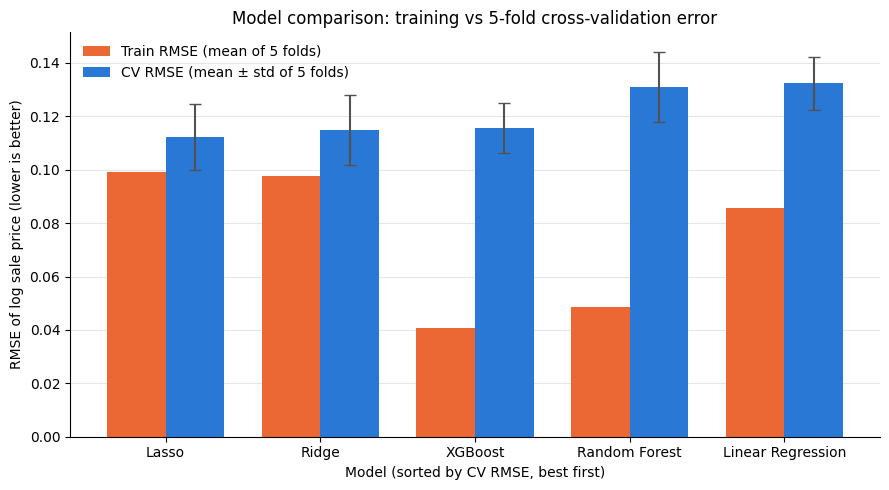

In [111]:
# Chart colours, used the same way in every chart below (colour follows the meaning, not the chart):
COLOR_CV = "#2a78d6"     # blue: cross-validation / test error (unseen houses)
COLOR_TRAIN = "#eb6834"  # orange: training error
COLOR_GRID = "#e5e5e3"   # light, so gridlines stay in the background


def style_axes(ax):
    """Recessive grid and no top/right frame, so the data stands out."""
    ax.grid(axis="y", color=COLOR_GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)


# One row per model, best (lowest CV RMSE) first.
cv_table = pd.DataFrame(list(cv_summary.values())).set_index("model").sort_values("CV RMSE")
cv_table["best params"] = cv_table["best params"].apply(
    lambda p: p if isinstance(p, dict) else "none (no hyperparameters)")
cv_table.round(4).to_csv("outputs/results/cv_results.csv")
print("5-fold CV results on the training set (RMSE on log sale price), best first:")
print(cv_table.round(4).to_string())

# Model-selection rule (fixed before the test set is used): lowest mean CV RMSE.
BEST_MODEL_NAME = cv_table.index[0]
print("\nBest model by CV RMSE:", BEST_MODEL_NAME)

# Bar chart: training vs CV error per model, CV error bars = std across the 5 folds.
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(cv_table))
width = 0.38
ax.bar(x - width / 2, cv_table["train RMSE"], width, color=COLOR_TRAIN,
       label="Train RMSE (mean of 5 folds)")
ax.bar(x + width / 2, cv_table["CV RMSE"], width, color=COLOR_CV,
       yerr=cv_table["CV RMSE std"], capsize=4, ecolor="#52514e",
       label="CV RMSE (mean ± std of 5 folds)")
ax.set_xticks(x, cv_table.index)
ax.set_xlabel("Model (sorted by CV RMSE, best first)")
ax.set_ylabel("RMSE of log sale price (lower is better)")
ax.set_title("Model comparison: training vs 5-fold cross-validation error")
ax.legend(frameon=False)
style_axes(ax)
fig.tight_layout()
fig.savefig("outputs/figures/model_comparison_cv_rmse.png", dpi=150)
plt.show()

**Result:** model ranking by 5-fold CV RMSE (log price), saved to `outputs/results/cv_results.csv`:

| Rank | Model | Train RMSE | CV RMSE (mean ± std) | Gap (CV − train) |
|---|---|---|---|---|
| 1 | **Lasso** | 0.0992 | **0.1123 ± 0.0122** | 0.0131 |
| 2 | Ridge | 0.0978 | 0.1148 ± 0.0131 | 0.0170 |
| 3 | XGBoost | 0.0408 | 0.1156 ± 0.0093 | 0.0748 |
| 4 | Random Forest | 0.0487 | 0.1312 ± 0.0131 | 0.0824 |
| 5 | Linear Regression | 0.0858 | 0.1324 ± 0.0100 | 0.0465 |

(The table's gaps are computed from unrounded values, so Linear Regression's shows 0.0465 rather than the 0.0466 calculated by hand in Section 7b.)

- **Selected model: Lasso** (lowest mean CV RMSE). The top three are close: the differences between Lasso, Ridge and XGBoost (0.0025–0.0033) are smaller than one fold-to-fold standard deviation (about 0.01). Lasso's advantage over Ridge is consistent, though (better on all 5 folds).
- **Bias–variance pattern:**
  - **Regularised linear models** (Lasso, Ridge) have small gaps (0.013–0.017): low variance.
  - **Tree ensembles** (XGBoost, Random Forest) have very low training error but large gaps (0.075–0.082): they fit the training houses far more closely than they generalise, so they are high-variance.
  - **Plain Linear Regression** sits in between (gap 0.047): it overfits more than its regularised versions.
- Regularisation is what makes the linear models win: the same model family goes from last (Linear Regression, 0.1324) to first (Lasso, 0.1123) once a penalty is added.

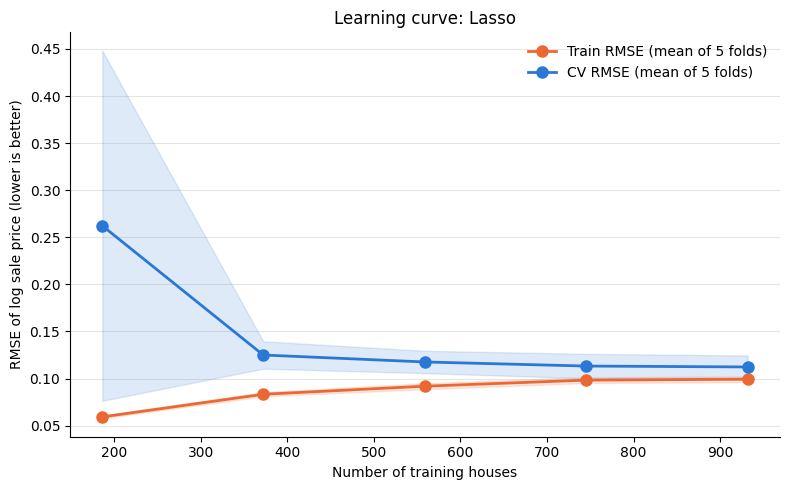

Learning curve (RMSE, mean of 5 folds):
 training houses  train RMSE  CV RMSE
             186      0.0592   0.2623
             372      0.0833   0.1250
             559      0.0919   0.1176
             745      0.0983   0.1133
             932      0.0992   0.1123


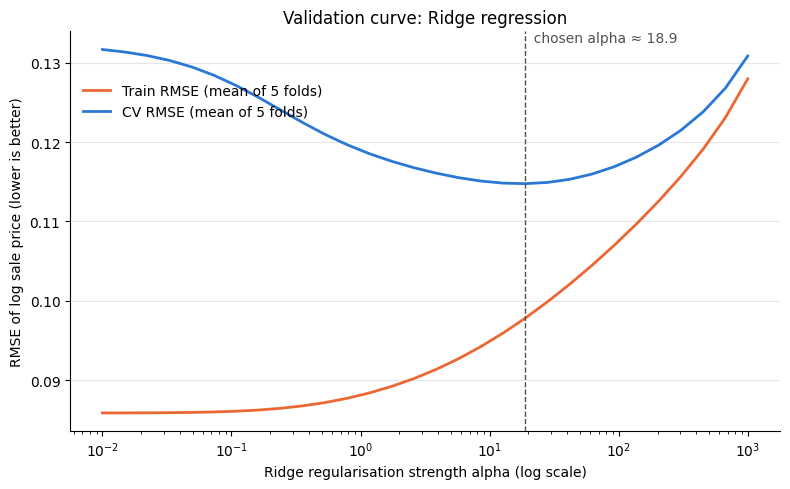

In [112]:
# The tuned pipeline for every model. Each search already refitted its best pipeline on all
# 1,166 training houses; Linear Regression has nothing to tune, so it is fitted here.
TUNED_PIPELINES = {
    "Linear Regression": make_model_pipeline(LinearRegression()).fit(X_train, y_train),
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_,
}
best_pipeline = TUNED_PIPELINES[BEST_MODEL_NAME]

# --- Learning curve for the best model -------------------------------------------------
# For each training size, the (unfitted copy of the) best pipeline is trained on that many
# houses from each CV training part and scored on the held-out fold; same 5 folds as before.
LC_FRACTIONS = np.linspace(0.2, 1.0, 5)  # 20% ... 100% of a fold's ~933 training houses
sizes, lc_train, lc_cv = learning_curve(
    best_pipeline, X_train, y_train, cv=CV, train_sizes=LC_FRACTIONS,
    scoring="neg_root_mean_squared_error",
)
lc_train, lc_cv = -lc_train, -lc_cv  # back to positive RMSE

fig, ax = plt.subplots(figsize=(8, 5))
for scores, color, label in [(lc_train, COLOR_TRAIN, "Train RMSE"), (lc_cv, COLOR_CV, "CV RMSE")]:
    mean, std = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(sizes, mean, marker="o", markersize=8, linewidth=2, color=color, label=f"{label} (mean of 5 folds)")
    ax.fill_between(sizes, mean - std, mean + std, color=color, alpha=0.15)  # ± 1 std across folds
ax.set_xlabel("Number of training houses")
ax.set_ylabel("RMSE of log sale price (lower is better)")
ax.set_title(f"Learning curve: {BEST_MODEL_NAME}")
ax.legend(frameon=False)
style_axes(ax)
fig.tight_layout()
slug = BEST_MODEL_NAME.lower().replace(" ", "_")
fig.savefig(f"outputs/figures/learning_curve_{slug}.png", dpi=150)
plt.show()

print("Learning curve (RMSE, mean of 5 folds):")
print(pd.DataFrame({"training houses": sizes, "train RMSE": lc_train.mean(axis=1),
                    "CV RMSE": lc_cv.mean(axis=1)}).round(4).to_string(index=False))

# --- Validation curve for Ridge alpha (reuses the grid-search scores, no extra fitting) ----
res = ridge_search.cv_results_
alphas = np.array(res["param_model__alpha"], dtype=float)
order = np.argsort(alphas)
ridge_best_alpha = ridge_search.best_params_["model__alpha"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(alphas[order], -res["mean_train_score"][order], linewidth=2, color=COLOR_TRAIN,
        label="Train RMSE (mean of 5 folds)")
ax.plot(alphas[order], -res["mean_test_score"][order], linewidth=2, color=COLOR_CV,
        label="CV RMSE (mean of 5 folds)")
ax.axvline(ridge_best_alpha, color="#52514e", linestyle="--", linewidth=1)
ax.text(ridge_best_alpha, ax.get_ylim()[1], f"  chosen alpha ≈ {ridge_best_alpha:.3g}",
        va="top", color="#52514e")
ax.set_xscale("log")
ax.set_xlabel("Ridge regularisation strength alpha (log scale)")
ax.set_ylabel("RMSE of log sale price (lower is better)")
ax.set_title("Validation curve: Ridge regression")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.9))
style_axes(ax)
fig.tight_layout()
fig.savefig("outputs/figures/validation_curve_ridge_alpha.png", dpi=150)
plt.show()

**Result:**

**Learning curve (Lasso):**

| Training houses | Train RMSE | CV RMSE |
|---|---|---|
| 186 | 0.0592 | 0.2623 |
| 372 | 0.0833 | 0.1250 |
| 559 | 0.0919 | 0.1176 |
| 745 | 0.0983 | 0.1133 |
| 932 | 0.0992 | 0.1123 |

- With few houses (186) the model overfits badly: the training error is low, the CV error is high (0.26), and its spread across folds is very large. With so few houses, many categories and feature combinations are seen only rarely.
- As data is added, the training error rises and the CV error falls. By 932 houses the two curves have nearly met (gap 0.013).
- The CV error is still falling slightly at full size (0.1133 → 0.1123 for the last step), so more data would probably help a little, but the curve is flattening. The remaining error is now mostly **bias**: to improve further, the model would need better features or more flexibility, not just more houses of the same kind.

**Validation curve (Ridge `alpha`):**
- At the smallest `alpha` values the model is close to plain Linear Regression: low training error and the highest CV error. That is overfitting (high variance).
- As `alpha` grows, the training error rises steadily, while the CV error first falls and then rises again. That gives a **U-shape** with its minimum at the chosen `alpha` ≈ 18.9.
- At the largest `alpha` (1,000), both errors are high and close together. The penalty shrinks the coefficients too much, which is underfitting (high bias).
- This is the bias–variance trade-off controlled by one regularisation parameter.

## 9–10. Final evaluation on the test set (used once)

**What:** the best model by CV RMSE (Section 8), already refitted on all 1,166 training houses, predicts the 292 test houses. This is the **only** time the test set is used. Nothing is tuned or changed after this point.

**Metrics (regression):** the brief lists accuracy, precision, recall and F1-score, but those are **classification** metrics: they count right/wrong class labels. We predict a continuous price, so we use the brief's "other relevant evaluation metrics":

| Metric | Scale | Meaning |
|---|---|---|
| **RMSE** | log price | root mean squared error; same metric as CV, so test and CV can be compared directly (≈ relative error) |
| **MAE** | US dollars | mean absolute error: the average size of a miss, in dollars |
| **R²** | log price and dollars | share of the variation in price explained by the model (1 = perfect, 0 = no better than predicting the average) |
| **MAPE** | % | mean absolute percentage error: the average miss as a percentage of the true price |

Predictions are made on log price and converted back to dollars with `np.expm1` for MAE, R² (USD) and MAPE.

**What to look for:**
- **Test RMSE close to the CV RMSE.** That would confirm the CV estimate was honest. A test RMSE much worse than CV would suggest the model selection overfitted the CV folds. Some difference either way is normal with only 292 houses.
- In the **predicted-vs-actual** plot, points should follow the diagonal line (perfect prediction).
- In the **residual** plot, errors should scatter evenly around 0 with no clear pattern. A funnel or curve would mean the model is systematically wrong for some price ranges.

Test-set metrics:
  model                                 : Lasso
  RMSE (log price)                      : 0.1096
  CV RMSE (log price), for comparison   : 0.1123
  MAE (USD)                             : 14,234.8154
  R2 (log price)                        : 0.9284
  R2 (USD)                              : 0.9307
  MAPE (%)                              : 8.2180
  test houses                           : 292


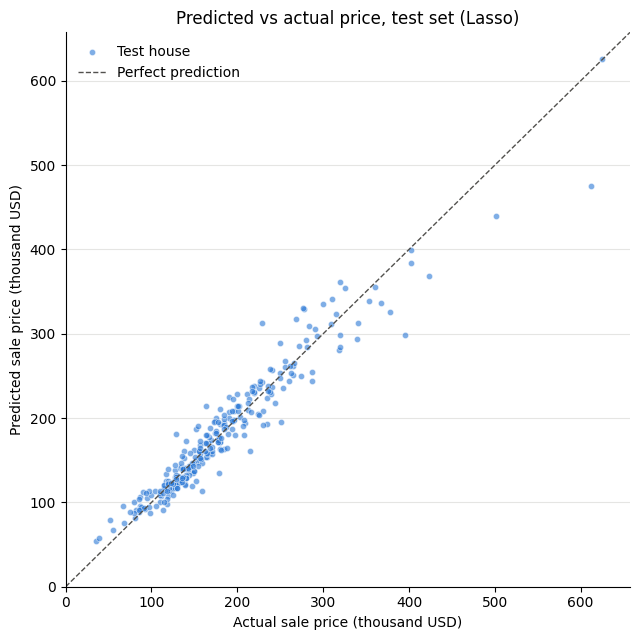

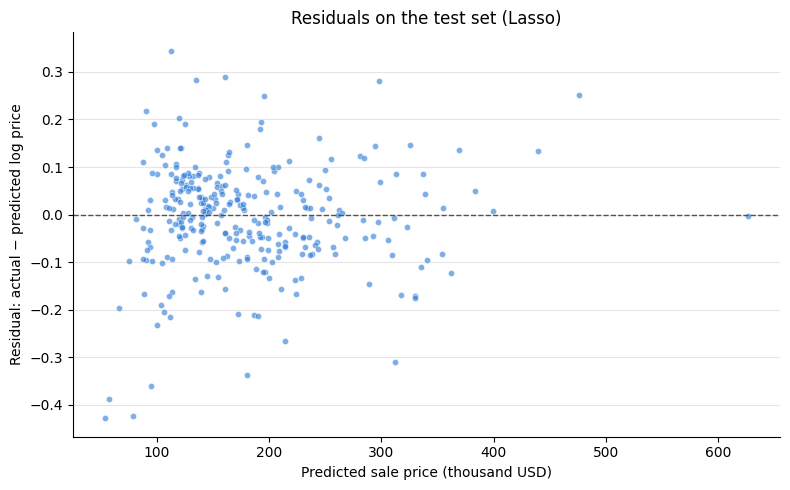


5 largest test errors (Kaggle Id = row + 1):
     actual (USD)  predicted (USD)  log residual
916       35311.0          54191.0        -0.428
710       52000.0          79479.0        -0.424
533       39300.0          57900.0        -0.387
874       66500.0          95299.0        -0.360
681      159434.0         112967.0         0.345


In [113]:
# The ONLY use of the test set: predict with the selected model, refitted on all training houses.
final_model = best_pipeline
y_pred_log = final_model.predict(X_test)

# Back to dollars for the dollar-based metrics and plots.
price_true = np.expm1(y_test)
price_pred = np.expm1(y_pred_log)

test_metrics = {
    "model": BEST_MODEL_NAME,
    "RMSE (log price)": root_mean_squared_error(y_test, y_pred_log),
    "CV RMSE (log price), for comparison": cv_table.loc[BEST_MODEL_NAME, "CV RMSE"],
    "MAE (USD)": mean_absolute_error(price_true, price_pred),
    "R2 (log price)": r2_score(y_test, y_pred_log),
    "R2 (USD)": r2_score(price_true, price_pred),
    "MAPE (%)": 100 * mean_absolute_percentage_error(price_true, price_pred),
    "test houses": len(y_test),
}
pd.DataFrame([test_metrics]).round(4).to_csv("outputs/results/test_metrics.csv", index=False)
print("Test-set metrics:")
for metric, value in test_metrics.items():
    print(f"  {metric:<38}: {value:,.4f}" if isinstance(value, float) else f"  {metric:<38}: {value}")

# Predicted vs actual price (dollars). The diagonal is a perfect prediction.
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(price_true / 1000, price_pred / 1000, s=20, alpha=0.6, color=COLOR_CV,
           edgecolor="white", linewidth=0.5, label="Test house")
lims = [0, max(price_true.max(), price_pred.max()) / 1000 * 1.05]
ax.plot(lims, lims, color="#52514e", linestyle="--", linewidth=1, label="Perfect prediction")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual sale price (thousand USD)")
ax.set_ylabel("Predicted sale price (thousand USD)")
ax.set_title(f"Predicted vs actual price, test set ({BEST_MODEL_NAME})")
ax.legend(frameon=False, loc="upper left")
style_axes(ax)
fig.tight_layout()
fig.savefig("outputs/figures/predicted_vs_actual_test.png", dpi=150)
plt.show()

# Residuals on the log scale (= approximate relative error) against the predicted price.
residuals = y_test - y_pred_log
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(price_pred / 1000, residuals, s=20, alpha=0.6, color=COLOR_CV,
           edgecolor="white", linewidth=0.5)
ax.axhline(0, color="#52514e", linestyle="--", linewidth=1)
ax.set_xlabel("Predicted sale price (thousand USD)")
ax.set_ylabel("Residual: actual − predicted log price")
ax.set_title(f"Residuals on the test set ({BEST_MODEL_NAME})")
style_axes(ax)
fig.tight_layout()
fig.savefig("outputs/figures/residuals_test.png", dpi=150)
plt.show()

# The largest misses, to discuss in the article (positive residual = model under-predicted).
worst = pd.DataFrame({"actual (USD)": price_true.round(0), "predicted (USD)": price_pred.round(0),
                      "log residual": residuals.round(3)}).reindex(residuals.abs().sort_values(ascending=False).index)
print("\n5 largest test errors (Kaggle Id = row + 1):")
print(worst.head(5).to_string())

**Result:** the selected model (**Lasso**) on the 292 test houses, saved to `outputs/results/test_metrics.csv`:

| Metric | Value |
|---|---|
| RMSE (log price) | **0.1096** (CV estimate was 0.1123) |
| MAE | **\$14,235** |
| R² (log price) | 0.9284 |
| R² (USD) | 0.9307 |
| MAPE | **8.22%** |

- **The CV estimate was honest:** the test RMSE (0.1096) is close to the CV RMSE (0.1123), and slightly better. The model generalises to unseen houses as expected, and model selection did not overfit the CV folds.
- **In plain terms:** on average a prediction misses by about \$14,200, or 8.2% of the true price. The model explains about 93% of the variation in sale prices.
- **Predicted vs actual:** most houses lie close to the diagonal, and the spread grows with price. Two of the three most expensive test houses (about \$500,000 and \$610,000) are predicted well **below** their price (about \$440,000 and \$475,000, read from the plot). The most expensive one (about \$625,000) is predicted almost exactly. The training set contains few very expensive houses, so the model has little data on that price range.
- **Residuals:** centred on 0 with no strong curve, but with a wider spread at low predicted prices. The four largest errors are all cheap houses that the model **over-predicted** by about 43–54% (actual \$35,311 / \$52,000 / \$39,300 / \$66,500 vs predicted \$54,191 / \$79,479 / \$57,900 / \$95,299). The fifth is a \$159,434 house predicted at \$112,967. Very cheap houses are probably unusual sales or properties in poor condition that the features do not fully describe. (This was not checked house by house.)

## 11. Location ablation (problem statement 2)

**What:** measures how much **location** information improves prediction, by re-running 5-fold CV of the best model (Section 8) with three versions of the `Neighborhood` feature and everything else unchanged:

| Version | `Neighborhood` is ... |
|---|---|
| **(a) no location** | dropped entirely (after imputation, which still uses it to fill `LotFrontage`) |
| **(b) one-hot** | one 0/1 column per neighbourhood in the training data; the version used by all models in Section 7, so its CV RMSE should match the best model's value in Section 8 exactly (a built-in check) |
| **(c) target encoding (Tier 1)** | **one** column: the mean log price of training houses in that neighbourhood |

An **ablation** removes or swaps one ingredient at a time and measures the change in error, so the effect can be attributed to that ingredient.

**How target encoding avoids leakage:** encoding a house by the average price of its neighbourhood uses the target (price), which is risky: a house's own price would leak into its own feature. scikit-learn's `TargetEncoder` prevents this by **cross-fitting**: during training, each house is encoded using neighbourhood averages computed from the *other* internal folds only. It also shrinks the averages of small neighbourhoods towards the overall mean. On top of that, the whole pipeline is refitted inside each of our 5 CV folds, so the held-out fold never contributes to any encoding.

**Fairness note:** all three versions use the hyperparameters tuned for version (b). Re-tuning each version separately might change the numbers slightly. That was not done, to keep the comparison to one ingredient.

**Tier 2** (a neighbourhood price lag based on earlier sales) is not implemented. It is listed as future work.

**What to look for:** the change in CV RMSE from (a) to (b), which shows how much location adds; and whether one target-encoded column (c) does as well as the many one-hot columns (b). Differences smaller than the fold-to-fold spread (std) should be described as small.

Location ablation, Lasso, 5-fold CV on the training set (RMSE of log sale price):
                                           train RMSE  CV RMSE  CV RMSE std                          CV RMSE per fold  change vs (a)
version                                                                                                                             
(a) no location                                0.1043   0.1155       0.0123   [0.1284, 0.098, 0.1147, 0.1066, 0.1296]         0.0000
(b) Neighborhood one-hot                       0.0992   0.1123       0.0122  [0.1252, 0.0947, 0.1119, 0.1036, 0.1261]        -0.0032
(c) Neighborhood target encoding (Tier 1)      0.1019   0.1137       0.0129    [0.127, 0.094, 0.1106, 0.1084, 0.1286]        -0.0017


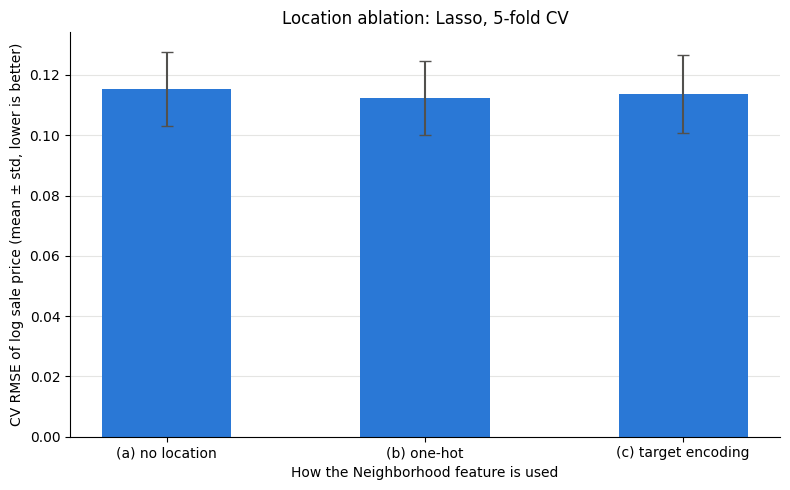

In [114]:
# Same model and tuned hyperparameters as the selected best model; only the location feature changes.
best_model_step = TUNED_PIPELINES[BEST_MODEL_NAME].named_steps["model"]

ABLATION_VERSIONS = [
    ("(a) no location", "none"),
    ("(b) Neighborhood one-hot", "onehot"),
    ("(c) Neighborhood target encoding (Tier 1)", "target"),
]
ablation_rows = []
for label, location in ABLATION_VERSIONS:
    pipeline = Pipeline([("prep", build_preprocessor(location=location)),
                         ("model", clone(best_model_step))])  # clone = unfitted copy, same settings
    scores = cross_validate(pipeline, X_train, y_train, cv=CV,
                            scoring="neg_root_mean_squared_error", return_train_score=True)
    ablation_rows.append({
        "version": label,
        "train RMSE": -scores["train_score"].mean(),
        "CV RMSE": -scores["test_score"].mean(),
        "CV RMSE std": scores["test_score"].std(),
        "CV RMSE per fold": np.round(-scores["test_score"], 4).tolist(),
    })

ablation = pd.DataFrame(ablation_rows).set_index("version")
ablation["change vs (a)"] = ablation["CV RMSE"] - ablation.loc["(a) no location", "CV RMSE"]
ablation.round(4).to_csv("outputs/results/ablation.csv")
print(f"Location ablation, {BEST_MODEL_NAME}, 5-fold CV on the training set (RMSE of log sale price):")
print(ablation.round(4).to_string())

# One series (CV RMSE), so no legend is needed; error bars = std across the 5 folds.
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(range(len(ablation)), ablation["CV RMSE"], width=0.5, color=COLOR_CV,
       yerr=ablation["CV RMSE std"], capsize=4, ecolor="#52514e")
ax.set_xticks(range(len(ablation)), ["(a) no location", "(b) one-hot", "(c) target encoding"])
ax.set_xlabel("How the Neighborhood feature is used")
ax.set_ylabel("CV RMSE of log sale price (mean ± std, lower is better)")
ax.set_title(f"Location ablation: {BEST_MODEL_NAME}, 5-fold CV")
style_axes(ax)
fig.tight_layout()
fig.savefig("outputs/figures/ablation_location_cv_rmse.png", dpi=150)
plt.show()

**Result:** location ablation with Lasso (tuned `alpha` ≈ 0.00067), saved to `outputs/results/ablation.csv`:

| Version | Train RMSE | CV RMSE (mean ± std) | Change vs (a) | CV per fold |
|---|---|---|---|---|
| (a) no location | 0.1043 | 0.1155 ± 0.0123 | — | 0.1284, 0.0980, 0.1147, 0.1066, 0.1296 |
| (b) Neighborhood one-hot | 0.0992 | **0.1123 ± 0.0122** | −0.0032 | 0.1252, 0.0947, 0.1119, 0.1036, 0.1261 |
| (c) Neighborhood target encoding (Tier 1) | 0.1019 | 0.1137 ± 0.0129 | −0.0017 | 0.1270, 0.0940, 0.1106, 0.1084, 0.1286 |

- **Built-in check passed:** version (b) reproduces Lasso's CV RMSE from Section 8 exactly (0.1123, same per-fold values).
- **Location helps, but only a little:** adding `Neighborhood` as one-hot lowers CV RMSE by 0.0032, about 3% relative, and improves **all 5 folds**. The gain is smaller than the fold-to-fold spread (std ≈ 0.012), so it is a consistent but small effect.
- **Target encoding (one column)** recovers about half of that gain (−0.0017, better on 4 of 5 folds). With a linear model, one number per neighbourhood captures less than a separate coefficient per neighbourhood.
- **Why the effect is small:** the other features already carry much of the location signal, e.g. quality, size, age, zoning (`MSZoning`) and lot features, which differ by neighbourhood. `Neighborhood` is also used to fill missing `LotFrontage` in all three versions. So this ablation measures the **extra** value of the neighbourhood label on top of a rich set of house features, not the total effect of location on price.
- Tier 2 (neighbourhood price lag) was not implemented.

## 12. Interpretation with SHAP (XGBoost)

**What:** **SHAP** (SHapley Additive exPlanations) splits each prediction into contributions from each feature. For one house, the prediction = the model's average prediction + the sum of that house's SHAP values. A positive SHAP value means the feature pushed this house's predicted log price **up**; a negative value pushed it **down**. `TreeExplainer` computes these exactly and quickly for tree models.

We explain the **XGBoost** model, as planned in problem statement 1 (an accurate gradient-boosting model, explained with SHAP), on the 292 test houses. Explaining predictions does not train anything, so this does not leak test information into the model. The model was already fixed in Section 9.

**Two plots:**
1. **Summary (beeswarm) plot, global view:** one row per feature (top 15), one dot per test house. Horizontal position = SHAP value (effect on predicted log price). Colour = the feature's value for that house (red = high, blue = low). Features are sorted by mean |SHAP value|, i.e. overall importance.
2. **Waterfall plot, one house:** how each feature moved one typical test house's prediction away from the average. The house is the one whose predicted price is closest to the median prediction.

**What to look for:** which features matter most, and in which direction (e.g. high `OverallQual` → red dots on the right = higher price); whether location (`Neighborhood_*`) features appear; whether the engineered features (`TotalSF`, `QualxSize`, ...) rank high. Note that SHAP explains what the **model** learned, which is not necessarily cause and effect in the housing market.

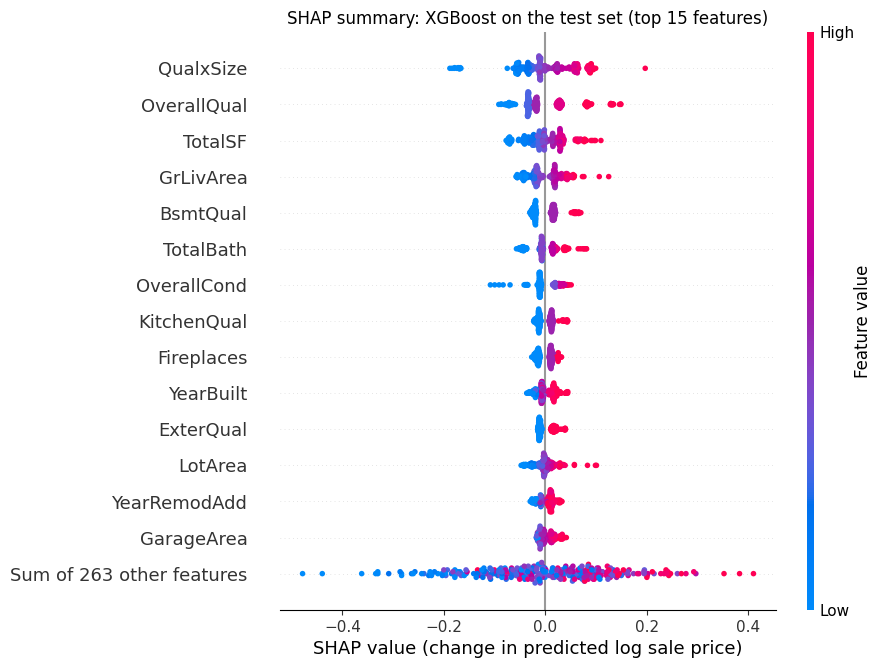

Top 15 features by mean |SHAP value| (log price units):
QualxSize       0.0442
OverallQual     0.0426
TotalSF         0.0288
GrLivArea       0.0283
BsmtQual        0.0225
TotalBath       0.0217
OverallCond     0.0193
KitchenQual     0.0144
Fireplaces      0.0144
YearBuilt       0.0141
ExterQual       0.0140
LotArea         0.0127
YearRemodAdd    0.0124
GarageArea      0.0116
1stFlrSF        0.0115


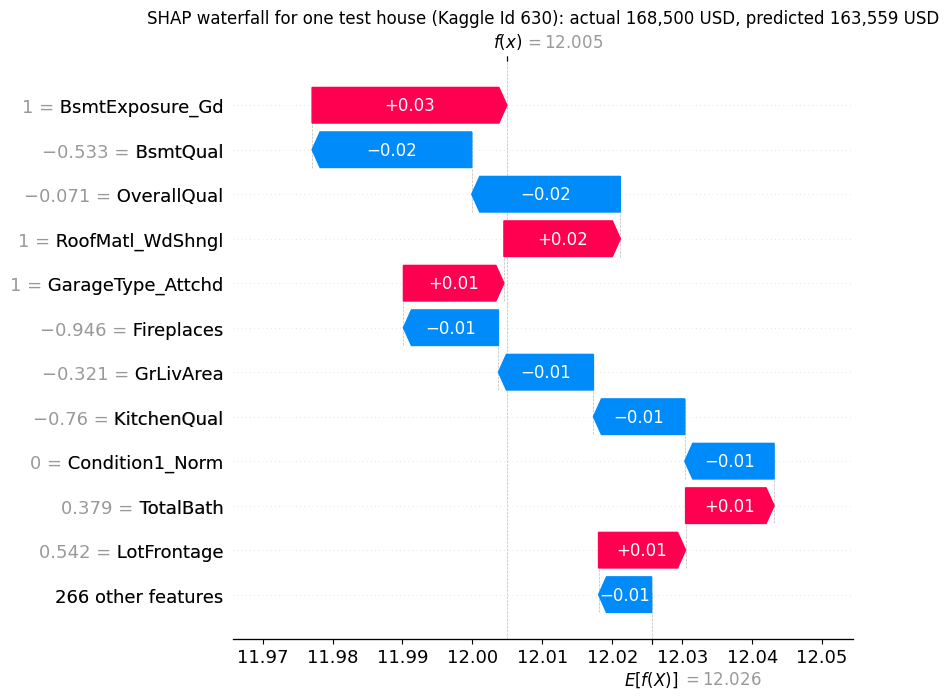

In [118]:
xgb_pipeline = xgb_search.best_estimator_  # tuned XGBoost, refitted on all training houses

# SHAP works on the model's own inputs: the preprocessed test features (same columns as in training).
X_test_xgb = xgb_pipeline.named_steps["prep"].transform(X_test)
explainer = shap.TreeExplainer(xgb_pipeline.named_steps["model"])
shap_values = explainer(X_test_xgb)
# Readable labels for the plots: drop the "num__" / "cat__" prefixes added by the ColumnTransformer.
shap_values.feature_names = [name.split("__", 1)[1] for name in X_test_xgb.columns]

# Global view: beeswarm summary of the 15 most important features.
shap.plots.beeswarm(shap_values, max_display=15, show=False)
fig = plt.gcf()
plt.title("SHAP summary: XGBoost on the test set (top 15 features)")
plt.xlabel("SHAP value (change in predicted log sale price)")
fig.savefig("outputs/figures/shap_summary_xgboost.png", dpi=150, bbox_inches="tight")
plt.show()

# Overall importance as a table: mean absolute SHAP value per feature.
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0),
                          index=shap_values.feature_names).sort_values(ascending=False)
print("Top 15 features by mean |SHAP value| (log price units):")
print(mean_abs_shap.head(15).round(4).to_string())

# Local view: one typical house = the test house whose predicted price is closest to the median prediction.
xgb_pred_log = xgb_pipeline.predict(X_test)
house = int(np.argmin(np.abs(xgb_pred_log - np.median(xgb_pred_log))))
shap.plots.waterfall(shap_values[house], max_display=12, show=False)
fig = plt.gcf()
# Prices written as "USD", not with "$": matplotlib reads text between two "$" signs as maths notation.
plt.title(f"SHAP waterfall for one test house (Kaggle Id {X_test.index[house] + 1}): "
          f"actual {np.expm1(y_test.iloc[house]):,.0f} USD, predicted {np.expm1(xgb_pred_log[house]):,.0f} USD")
fig.savefig("outputs/figures/shap_waterfall_xgboost.png", dpi=150, bbox_inches="tight")
plt.show()

**Result:**

**Global importance (mean |SHAP value|, XGBoost, test set):** `QualxSize` 0.044, `OverallQual` 0.043, `TotalSF` 0.029, `GrLivArea` 0.028, `BsmtQual` 0.023, `TotalBath` 0.022, `OverallCond` 0.019, `KitchenQual` 0.014, `Fireplaces` 0.014, `YearBuilt` 0.014, `ExterQual` 0.014, `LotArea` 0.013, `YearRemodAdd` 0.012, `GarageArea` 0.012, `1stFlrSF` 0.012.

- **Quality and size dominate.** The two most important features are the engineered interaction `QualxSize` and `OverallQual`, followed by the total and above-ground living areas.
- **Engineered features matter:** 3 of the top 6 are ours (`QualxSize` 1st, `TotalSF` 3rd, `TotalBath` 6th). This supports the feature engineering in Section 5.
- **Directions make sense (beeswarm):** high values (red) of quality, size, bathrooms, fireplaces and build year push the predicted price **up**, and low values (blue) push it **down**.
- **No neighbourhood column is in XGBoost's top 15.** This is consistent with the small location effect in the ablation (Section 11): the quality and size features already carry much of the location signal. Each one-hot neighbourhood column also applies to only a small share of houses, which lowers its average |SHAP| even if it matters a lot for those houses.
- **Waterfall (one typical test house, Kaggle Id 630):** actual \$168,500, predicted \$163,559. The prediction (12.005 on the log scale) sits just below the model's average (12.026). Small positive pushes (e.g. good basement exposure, wood-shingle roof, attached garage) and small negative pushes (e.g. below-average basement and kitchen quality, overall quality, fewer fireplaces) nearly cancel out. Note: the numbers to the left of each feature are its **scaled** values (standard deviations from the training mean), because the model sees standardised inputs. For example, `OverallQual = −0.071` means very slightly below average quality.
- SHAP explains what the **model** learned from the data. It shows association, not cause and effect in the housing market.

## 13. Architecture diagram

**What:** draws the workflow implemented in this notebook as one figure, `outputs/figures/architecture.png`, for the article's architecture section. Each box is a real step above, with the numbers from this run.

**Why generated from code:** the diagram then matches the pipeline exactly (step order, set sizes, number of models and tuning budget). The best model's name is filled in from Section 8.

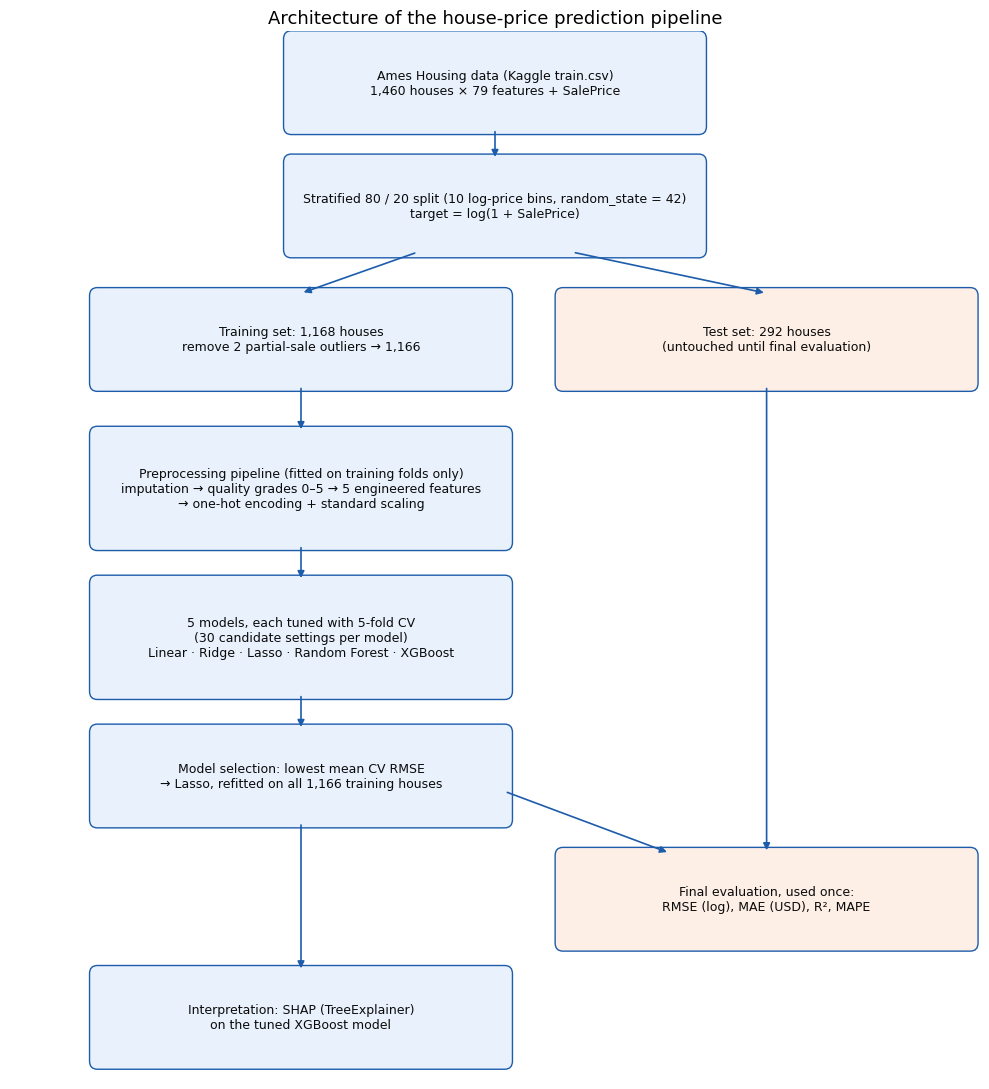

In [116]:
BOX_FILL, BOX_EDGE, TEST_FILL = "#e8f1fc", "#1c5cab", "#fdeee6"


def draw_box(ax, x, y, text, width=0.42, height=0.085, fill=BOX_FILL):
    """Draw a rounded box centred at (x, y) in axes coordinates, with centred text."""
    ax.add_patch(FancyBboxPatch((x - width / 2, y - height / 2), width, height,
                                boxstyle="round,pad=0.008", facecolor=fill, edgecolor=BOX_EDGE))
    ax.text(x, y, text, ha="center", va="center", fontsize=9, color="#0b0b0b")


def draw_arrow(ax, start, end):
    """Arrow from start=(x, y) to end=(x, y) in axes coordinates."""
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", color=BOX_EDGE, lw=1.2))


LEFT, RIGHT, CENTRE = 0.30, 0.78, 0.50
n_test = len(X_test)
n_train_raw, n_train = len(X_train) + len(outlier_labels), len(X_train)

fig, ax = plt.subplots(figsize=(10, 11))
ax.set_axis_off()

draw_box(ax, CENTRE, 0.95, f"Ames Housing data (Kaggle train.csv)\n{len(df):,} houses × 79 features + SalePrice")
draw_box(ax, CENTRE, 0.83, "Stratified 80 / 20 split (10 log-price bins, random_state = 42)\ntarget = log(1 + SalePrice)")
draw_box(ax, LEFT, 0.70, f"Training set: {n_train_raw:,} houses\nremove {len(outlier_labels)} partial-sale outliers → {n_train:,}")
draw_box(ax, RIGHT, 0.70, f"Test set: {n_test} houses\n(untouched until final evaluation)", fill=TEST_FILL)
draw_box(ax, LEFT, 0.555, "Preprocessing pipeline (fitted on training folds only)\n"
         "imputation → quality grades 0–5 → 5 engineered features\n→ one-hot encoding + standard scaling",
         height=0.105)
draw_box(ax, LEFT, 0.41, f"5 models, each tuned with 5-fold CV\n({N_CANDIDATES} candidate settings per model)\n"
         "Linear · Ridge · Lasso · Random Forest · XGBoost", height=0.105)
draw_box(ax, LEFT, 0.275, f"Model selection: lowest mean CV RMSE\n→ {BEST_MODEL_NAME}, refitted on all {n_train:,} training houses")
draw_box(ax, RIGHT, 0.155, "Final evaluation, used once:\nRMSE (log), MAE (USD), R², MAPE", fill=TEST_FILL)
draw_box(ax, LEFT, 0.04, "Interpretation: SHAP (TreeExplainer)\non the tuned XGBoost model")

draw_arrow(ax, (CENTRE, 0.905), (CENTRE, 0.875))
draw_arrow(ax, (0.42, 0.785), (LEFT, 0.745))
draw_arrow(ax, (0.58, 0.785), (RIGHT, 0.745))
draw_arrow(ax, (LEFT, 0.655), (LEFT, 0.61))
draw_arrow(ax, (LEFT, 0.50), (LEFT, 0.465))
draw_arrow(ax, (LEFT, 0.355), (LEFT, 0.32))
draw_arrow(ax, (LEFT + 0.21, 0.26), (RIGHT - 0.1, 0.20))   # selected model -> test evaluation
draw_arrow(ax, (RIGHT, 0.655), (RIGHT, 0.20))              # test data -> test evaluation
draw_arrow(ax, (LEFT, 0.23), (LEFT, 0.085))

ax.set_xlim(0, 1)
ax.set_ylim(-0.02, 1.0)
ax.set_title("Architecture of the house-price prediction pipeline", fontsize=13)
fig.tight_layout()
fig.savefig("outputs/figures/architecture.png", dpi=150, bbox_inches="tight")
plt.show()

## 14. Collect the outputs

**What:** shows every saved figure and prints every CSV table, each preceded by a `FILE:` line with its path. It also packs the `outputs/` folder into `outputs.zip`.

**Why:** in Colab, files in `/content/` are deleted when the session ends. Displaying the saved PNG files (not re-drawn copies) and printing the CSVs stores exact copies inside this notebook's outputs. The files can then be restored into the repository's `outputs/` folder from the `.ipynb` file, even where Colab's download button is not available.

FILE: outputs/figures/ablation_location_cv_rmse.png


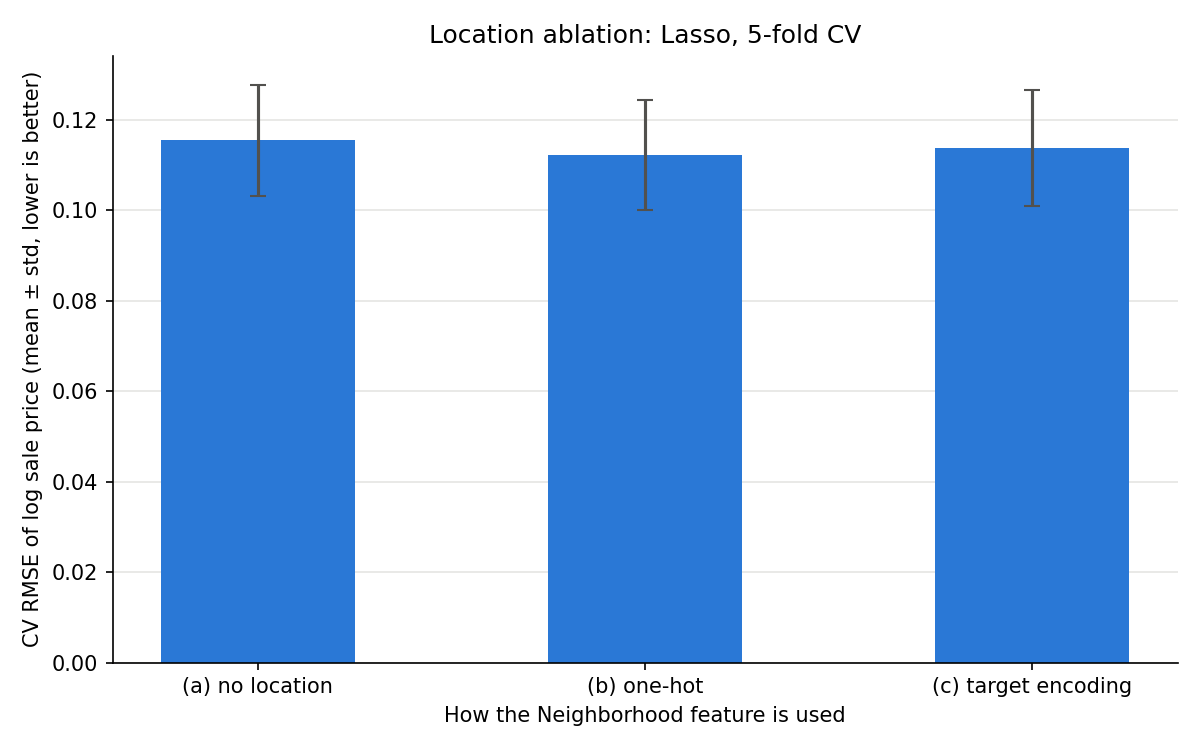

FILE: outputs/figures/architecture.png


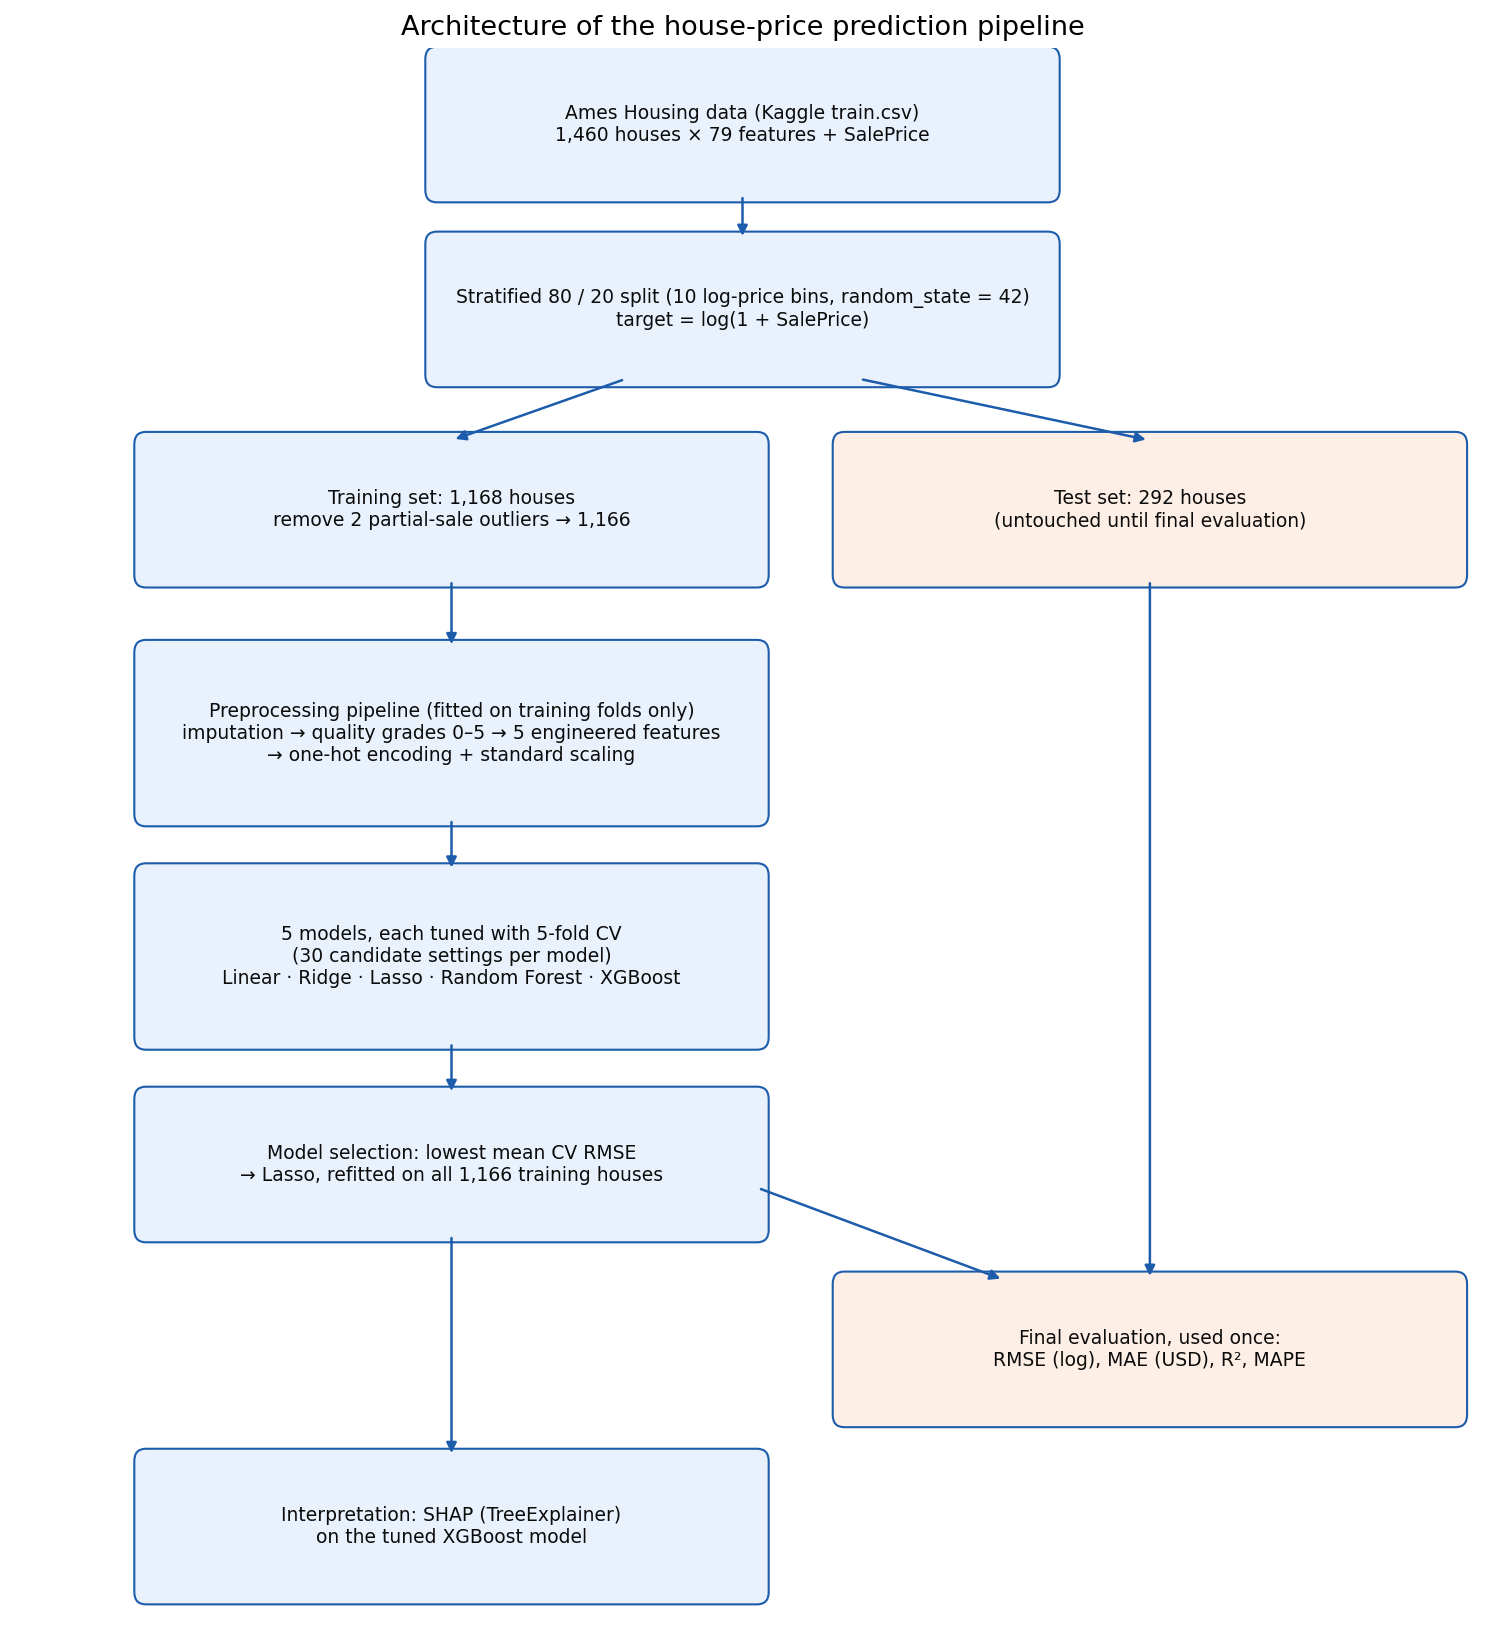

FILE: outputs/figures/learning_curve_lasso.png


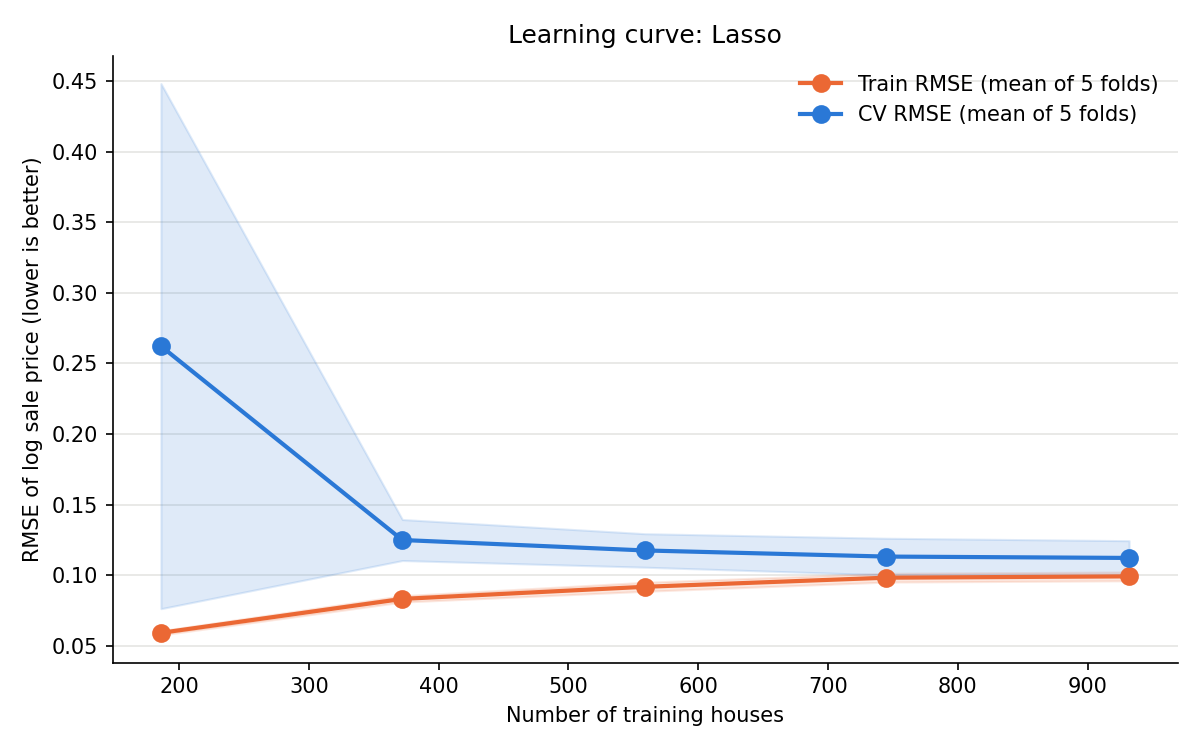

FILE: outputs/figures/model_comparison_cv_rmse.png


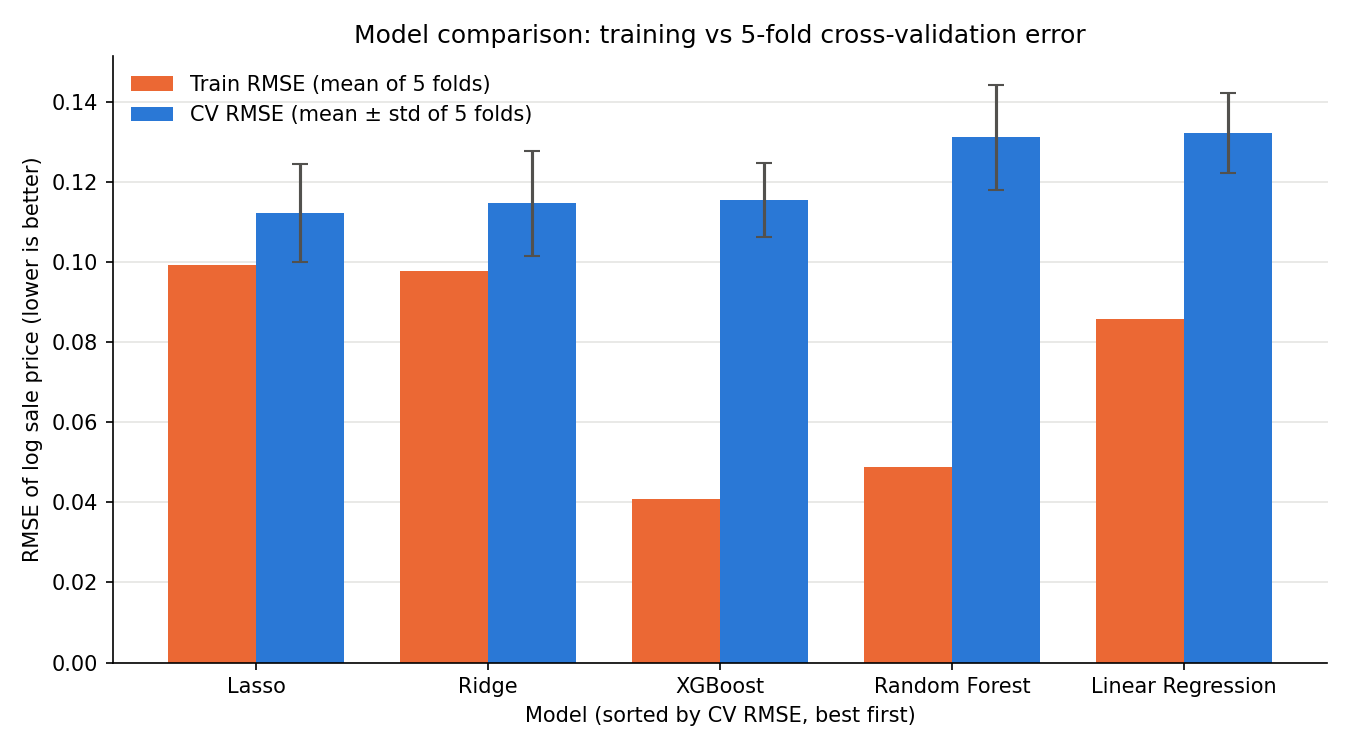

FILE: outputs/figures/predicted_vs_actual_test.png


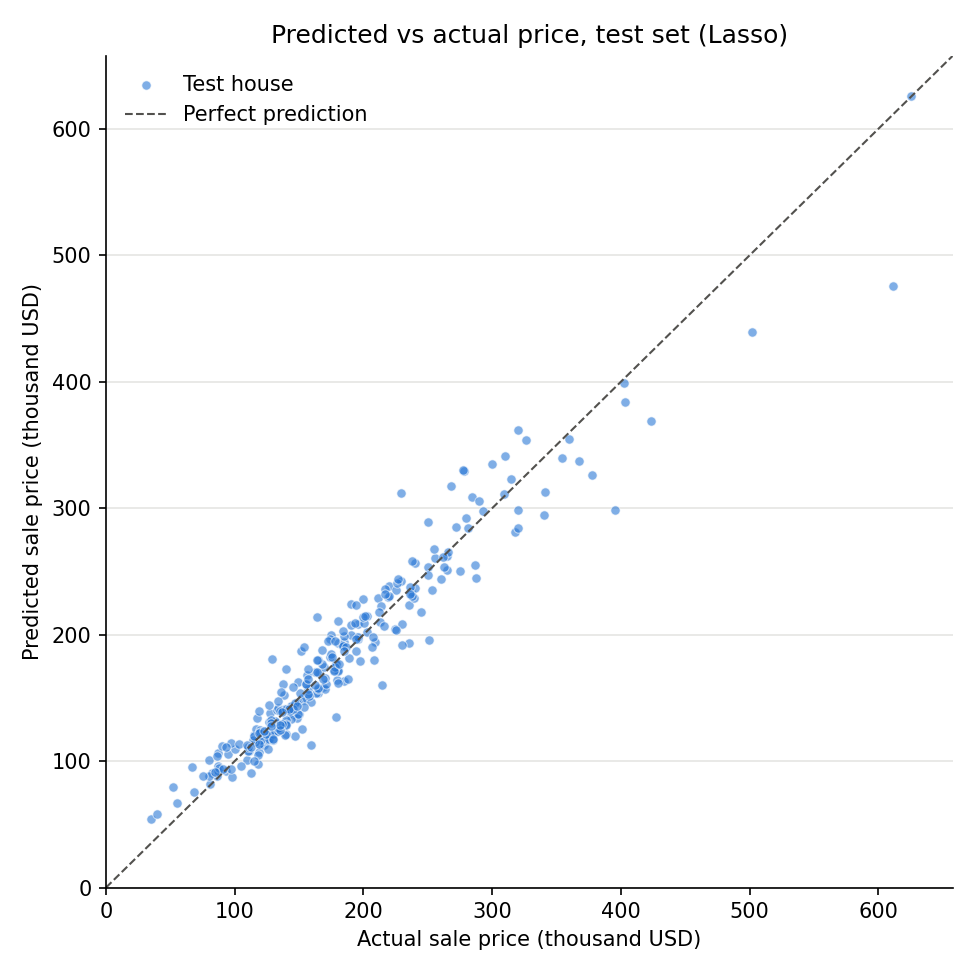

FILE: outputs/figures/residuals_test.png


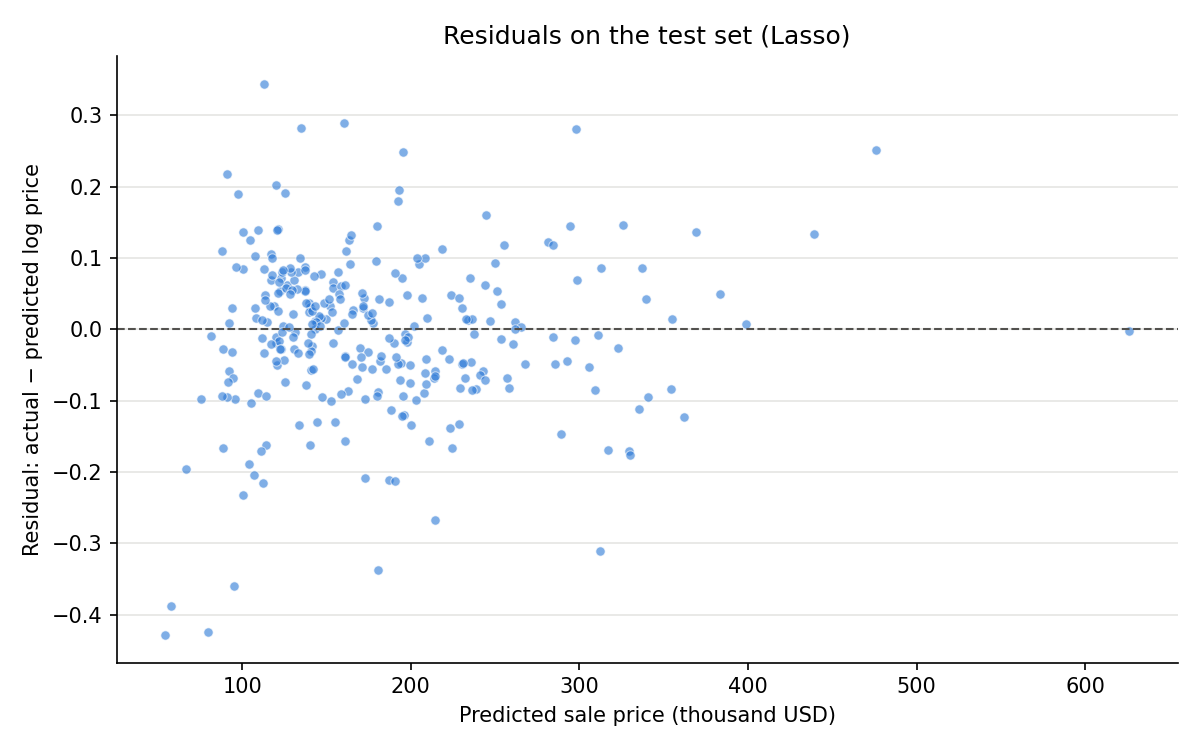

FILE: outputs/figures/shap_summary_xgboost.png


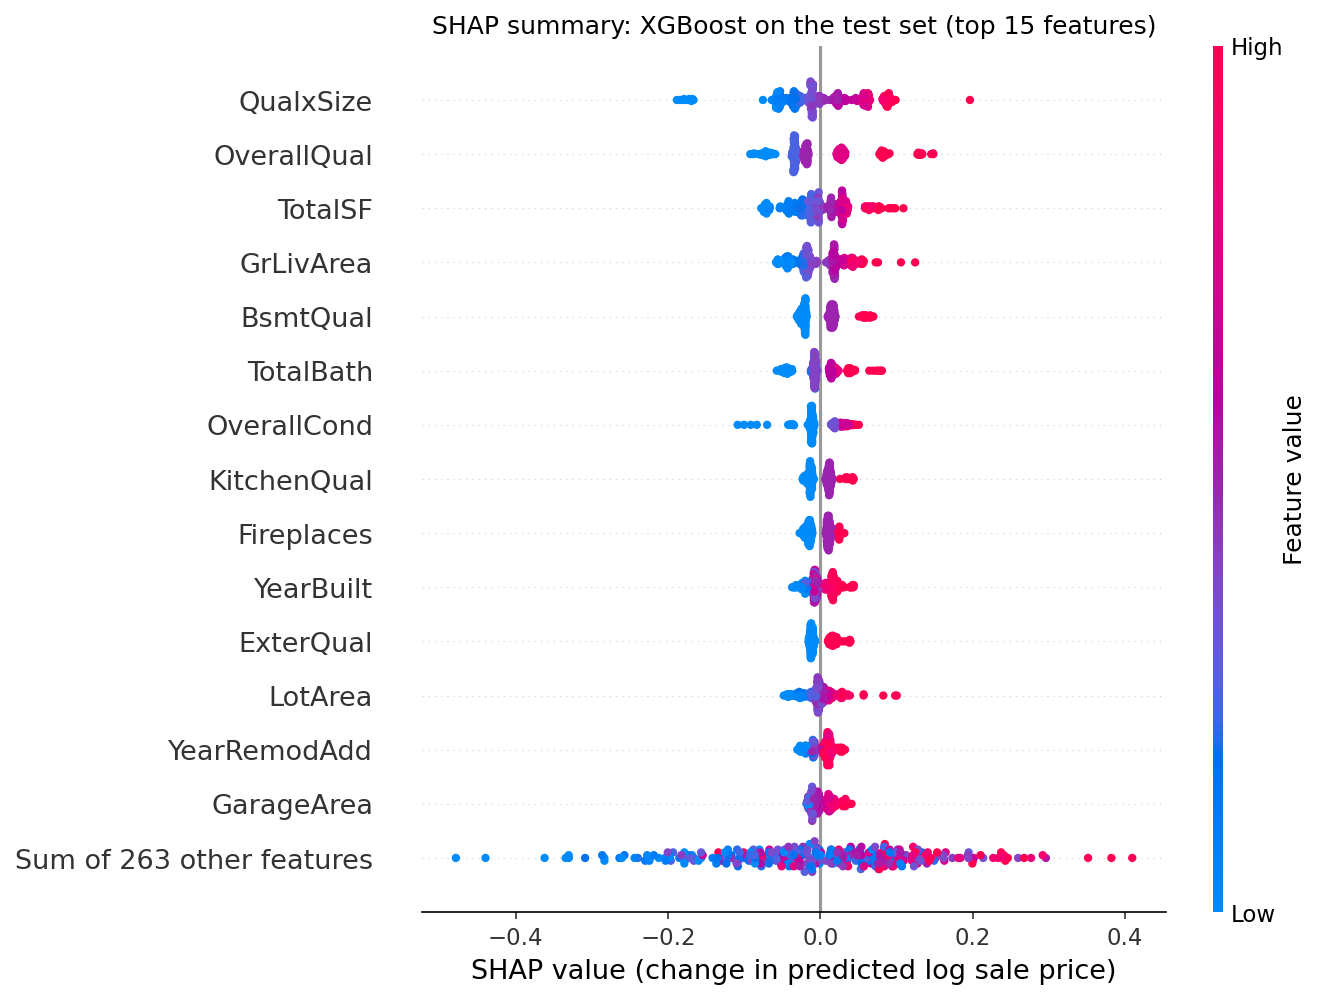

FILE: outputs/figures/shap_waterfall_xgboost.png


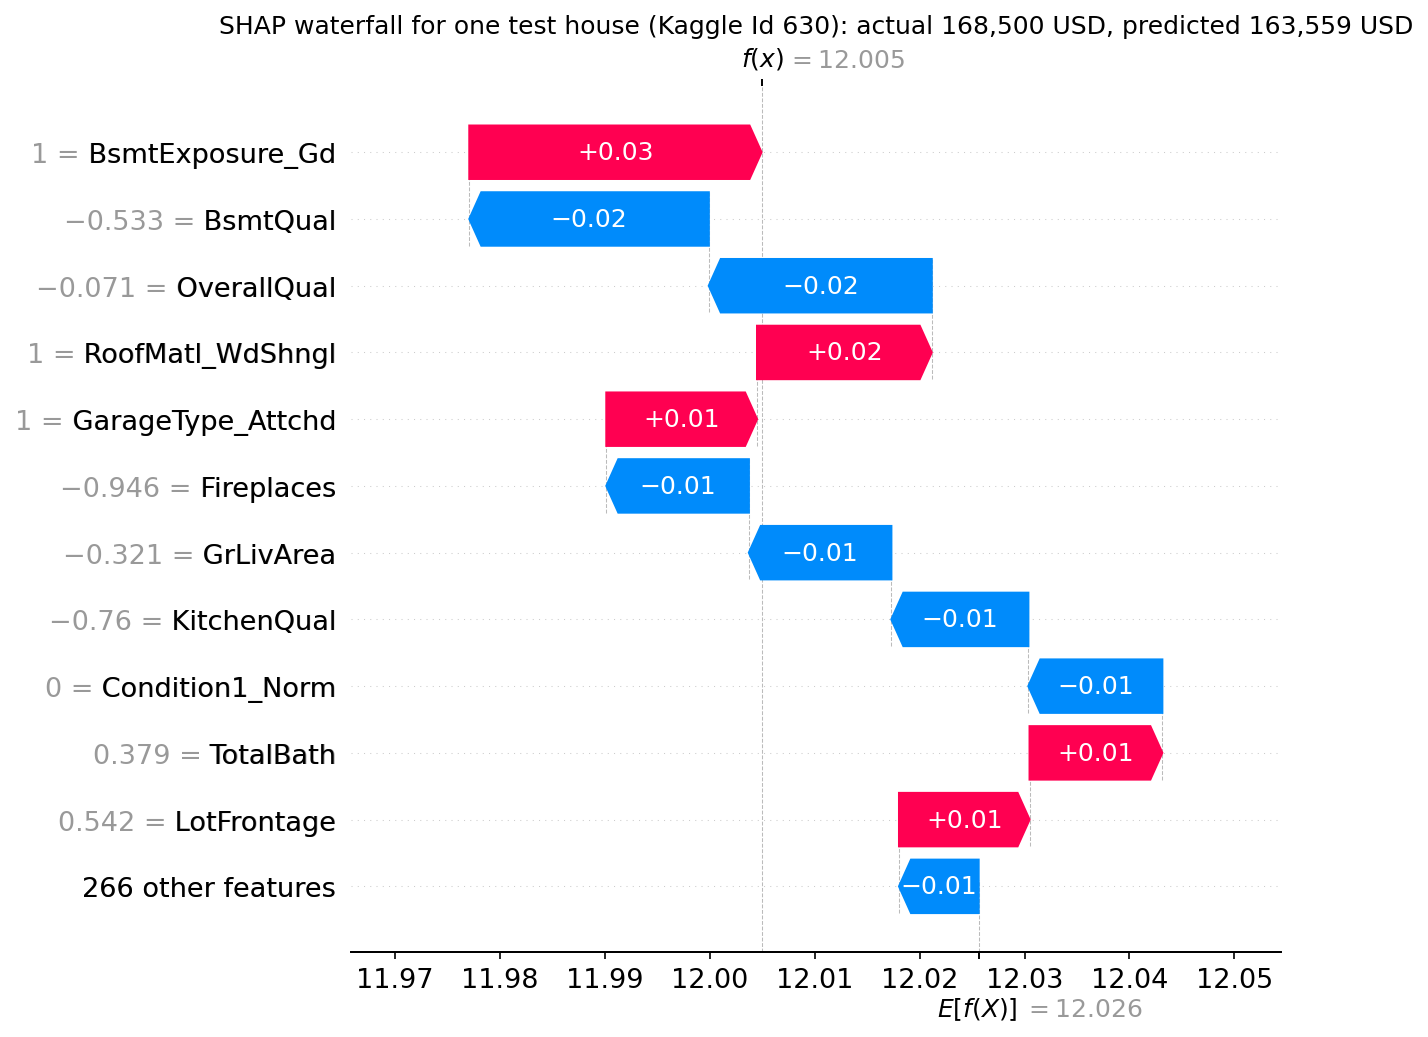

FILE: outputs/figures/train_grlivarea_vs_saleprice.png


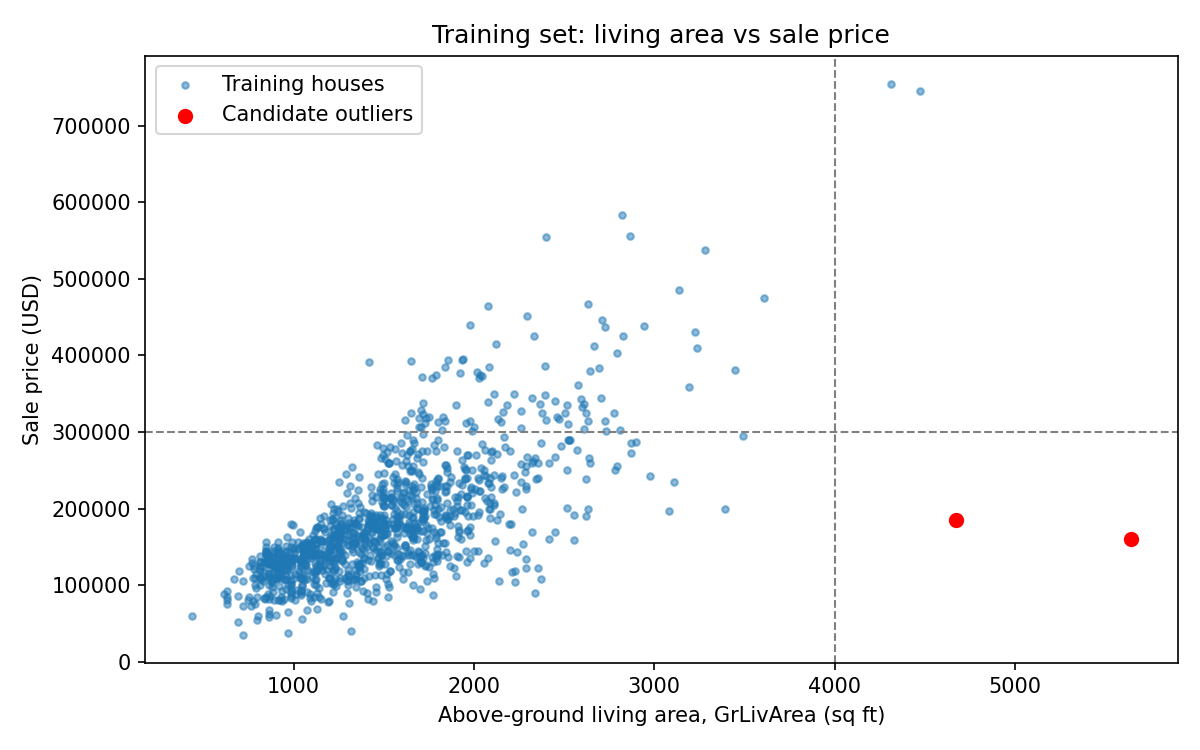

FILE: outputs/figures/validation_curve_ridge_alpha.png


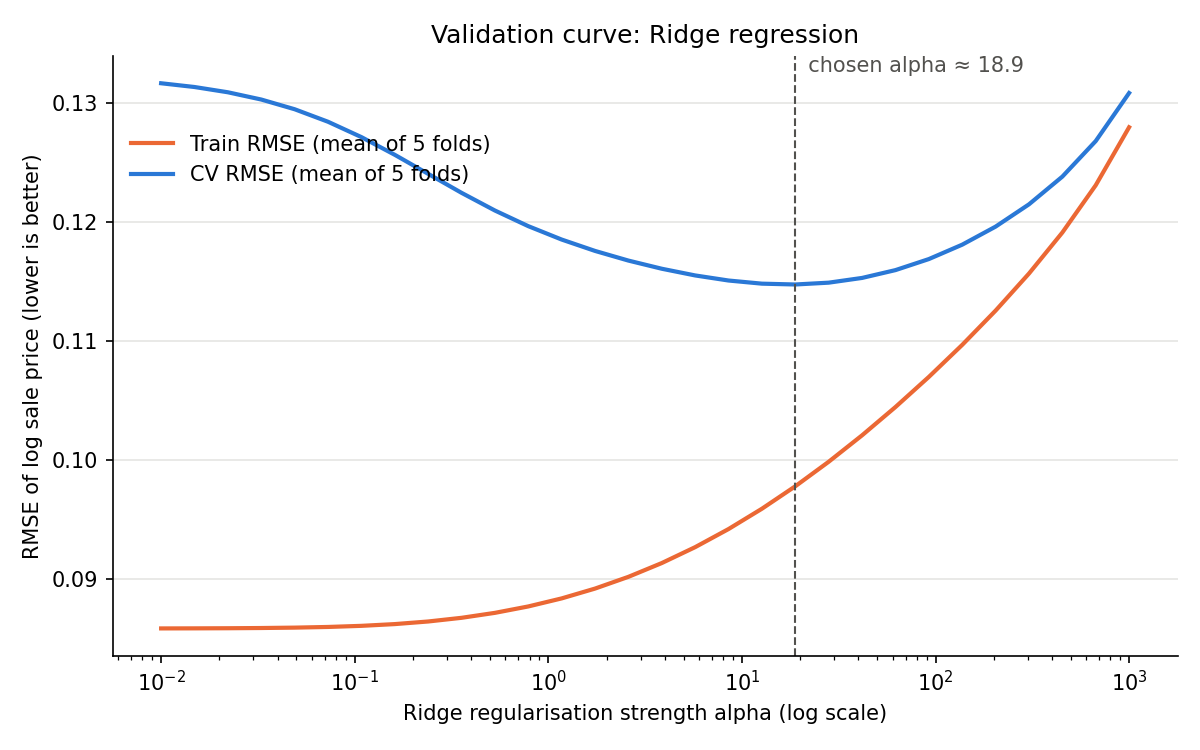

FILE: outputs/results/ablation.csv
version,train RMSE,CV RMSE,CV RMSE std,CV RMSE per fold,change vs (a)
(a) no location,0.1043,0.1155,0.0123,"[0.1284, 0.098, 0.1147, 0.1066, 0.1296]",0.0
(b) Neighborhood one-hot,0.0992,0.1123,0.0122,"[0.1252, 0.0947, 0.1119, 0.1036, 0.1261]",-0.0032
(c) Neighborhood target encoding (Tier 1),0.1019,0.1137,0.0129,"[0.127, 0.094, 0.1106, 0.1084, 0.1286]",-0.0017

END FILE: outputs/results/ablation.csv
FILE: outputs/results/cv_results.csv
model,train RMSE,CV RMSE,CV RMSE std,gap (CV - train),best params,features kept
Lasso,0.0992,0.1123,0.0122,0.0131,{'alpha': 0.0006723357536499335},92.0
Ridge,0.0978,0.1148,0.0131,0.017,{'alpha': 18.873918221350976},
XGBoost,0.0408,0.1156,0.0093,0.0748,"{'subsample': 0.8, 'n_estimators': 1500, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.1}",
Random Forest,0.0487,0.1312,0.0131,0.0824,"{'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.33, 'max_depth': 30}",
Linear Regression,0.0858,0.1324,0.01,

In [119]:
from IPython.display import Image, display

# Colab files disappear when the session ends. Showing each saved file in this cell's output
# stores an exact copy inside the notebook, so the files can be recovered from the .ipynb itself.
# Each figure is preceded by a "FILE:" line naming it; each CSV is printed in full.
for folder in ["outputs/figures", "outputs/results"]:
    for name in sorted(os.listdir(folder)):
        path = f"{folder}/{name}"
        print(f"FILE: {path}")
        if name.endswith(".png"):
            display(Image(filename=path))       # the exact 150-dpi PNG written by savefig
        elif name.endswith(".csv"):
            with open(path, encoding="utf-8") as f:
                print(f.read())
            print(f"END FILE: {path}")

archive = shutil.make_archive("outputs", "zip", root_dir=".", base_dir="outputs")
print("Zip archive (alternative, if downloads work in your environment):", os.path.abspath(archive))